# ACL Milestone 1 — Formula 1 Podium Prediction
## Integrated implementation: work packages 1–20
This notebook implements audit/cleaning, an explicit starter cohort, historical analyses,
leakage-safe features, logistic regression, and random forest. The later sections add the shallow NN, controlled experiments, XAI/inference, and a frozen three-model test evaluation. Team review, Kaggle synchronization and official submission remain pending. Raw CSVs are immutable. Test years 2022–2024 are reserved for final evaluation.

Source: [assignment-cited F1 dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020).
Attach that dataset to Kaggle, then Run All. Local execution runs from repository root.
The historical questions use outcomes descriptively; model selection uses training/validation only.

In [1]:
from pathlib import Path
import os, sys
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists() and (PROJECT_ROOT.parent / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if (PROJECT_ROOT / '.deps').exists():
    sys.path.insert(0, str(PROJECT_ROOT / '.deps'))
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT_ROOT / '.mplconfig'))
OUT = Path('/kaggle/working/acl_m1') if Path('/kaggle/input').exists() else PROJECT_ROOT/'outputs'/'batch2'
OUT.mkdir(parents=True, exist_ok=True)
from IPython.display import display, Markdown, Image
"""Milestone 1 work packages 1–10. Functions are embedded in the Kaggle notebook."""
from pathlib import Path
import hashlib
import json
import platform
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve, auc,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
import sklearn
import joblib

SEED = 42
KEY = ['raceId', 'driverId']
DATASET = 'https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020'
PK = {
 'circuits':['circuitId'], 'constructors':['constructorId'],
 'constructor_results':['constructorResultsId'], 'constructor_standings':['constructorStandingsId'],
 'drivers':['driverId'], 'driver_standings':['driverStandingsId'], 'races':['raceId'],
 'results':['resultId'], 'qualifying':['qualifyId'], 'lap_times':['raceId','driverId','lap'],
 'pit_stops':['raceId','driverId','stop'], 'sprint_results':['resultId'],
 'seasons':['year'], 'status':['statusId']}
FK = {'races':[('circuitId','circuits','circuitId'),('year','seasons','year')]}
for _name in ['constructor_results','constructor_standings','driver_standings',
              'qualifying','results','sprint_results','lap_times','pit_stops']:
    FK[_name] = [('raceId','races','raceId')]
    if _name not in ['constructor_results','constructor_standings']:
        FK[_name].append(('driverId','drivers','driverId'))
    if _name not in ['driver_standings','lap_times','pit_stops']:
        FK[_name].append(('constructorId','constructors','constructorId'))
    if _name in ['results','sprint_results']:
        FK[_name].append(('statusId','status','statusId'))

NUMERIC = {'number','grid','position','positionOrder','points','laps','milliseconds',
 'fastestLap','rank','fastestLapSpeed','lap','stop','year','round','wins','lat','lng','alt'}

COUNTRY = {'British':'UK','German':'Germany','Spanish':'Spain','Finnish':'Finland',
 'Japanese':'Japan','French':'France','Polish':'Poland','Brazilian':'Brazil','Italian':'Italy',
 'Australian':'Australia','Austrian':'Austria','American':'USA','Dutch':'Netherlands',
 'Colombian':'Colombia','Portuguese':'Portugal','Canadian':'Canada','Indian':'India',
 'Hungarian':'Hungary','Irish':'Ireland','Danish':'Denmark','Argentine':'Argentina',
 'Argentinian':'Argentina','Czech':'Czech Republic','Malaysian':'Malaysia','Swiss':'Switzerland',
 'Belgian':'Belgium','Monegasque':'Monaco','Swedish':'Sweden','Venezuelan':'Venezuela',
 'New Zealander':'New Zealand','Chilean':'Chile','Mexican':'Mexico','South African':'South Africa',
 'Liechtensteiner':'Liechtenstein','Rhodesian':'Zimbabwe','Uruguayan':'Uruguay','Thai':'Thailand',
 'East German':'Germany','Russian':'Russia','Indonesian':'Indonesia','Chinese':'China'}

MECHANICAL = {'Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical',
 'Radiator','Suspension','Brakes','Differential','Overheating','Mechanical','Driveshaft',
 'Fuel pressure','Water pressure','Throttle','Steering','Electronics','Heat shield fire',
 'Exhaust','Oil leak','Water leak','Fuel pump','Track rod','Oil pressure','Engine fire',
 'Engine misfire','Pneumatics','Wheel bearing','Fuel system','Oil line','Launch control',
 'Power loss','Drivetrain','Ignition','Battery','Halfshaft','Crankshaft','Alternator',
 'Oil pump','Fuel leak','Injection','Distributor','Turbo','CV joint','Water pump',
 'Spark plugs','Fuel pipe','Oil pipe','Axle','Water pipe','Magneto','Supercharger',
 'Power Unit','ERS','Cooling system'}

ACCIDENT_DRIVER_REG = {'Accident','Collision','Spun off','Disqualified','Underweight',
 'Collision damage','Fatal accident','Driver unwell','Injured','Injury','Illness','Physical','Eye injury'}



## 1–2. Source inventory and integrity audit

Verify all 14 source tables, candidate keys, columns, missingness and foreign keys. Fail on key/orphan problems; record source hashes.

In [2]:
def markdown_table(frame, digits=4):
    """No optional tabulate dependency needed on Kaggle."""
    def cell(x):
        if pd.isna(x): return '—'
        if isinstance(x, (float, np.floating)): return f'{x:.{digits}f}'
        return str(x).replace('|', '/')
    return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
        '| '+' | '.join(['---']*len(frame.columns))+' |']+
        ['| '+' | '.join(cell(v) for v in r)+' |' for r in frame.itertuples(index=False,name=None)])


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8')


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def locate_data(project_root):
    """Use a single complete dataset directory; never mix unrelated input CSVs."""
    project_root = Path(project_root)
    if Path('/kaggle/input').exists():
        candidates = [p.parent for p in Path('/kaggle/input').rglob('results.csv')
                      if set(PK).issubset({x.stem for x in p.parent.glob('*.csv')})]
        if len(candidates) != 1:
            raise ValueError(f'Attach exactly one complete F1 dataset; found {candidates}')
        return candidates[0]
    raw = project_root/'data'/'raw'
    raw.mkdir(parents=True,exist_ok=True)
    archive = project_root/'data'/'f1-source.zip'
    if archive.exists():
        with zipfile.ZipFile(archive) as z:
            for name in PK:
                dest = raw/f'{name}.csv'
                contents = z.read(f'{name}.csv')
                if dest.exists():
                    assert dest.read_bytes() == contents, f'Refusing to overwrite changed raw file: {dest}'
                else:
                    dest.write_bytes(contents)
    assert set(PK).issubset({x.stem for x in raw.glob('*.csv')}), 'Download the assignment dataset first.'
    return raw


def audit_data(data_dir, out):
    out = Path(out)
    out.mkdir(parents=True,exist_ok=True)
    paths = {n:Path(data_dir)/f'{n}.csv' for n in PK}
    hashes = {n:file_hash(p) for n,p in paths.items()}
    raw = {n:pd.read_csv(p,keep_default_na=False) for n,p in paths.items()}
    audit, columns, relationships = [], [], []
    for name, df in raw.items():
        missing = df.apply(lambda s:s.astype(str).str.strip().isin(['',r'\N']))
        pk_null = int(missing[PK[name]].any(axis=1).sum())
        dup = int(df.duplicated(PK[name]).sum())
        audit.append({'table':name,'rows':len(df),'columns':len(df.columns),
                      'primary_key':', '.join(PK[name]),'null_PK_rows':pk_null,
                      'duplicate_PK_rows':dup,'missing_cells':int(missing.sum().sum())})
        for c in df:
            columns.append({'table':name,'column':c,'raw_dtype':str(df[c].dtype),
                            'missing_count':int(missing[c].sum()),'missing_fraction':float(missing[c].mean())})
        for c,parent,pc in FK.get(name,[]):
            source = df.loc[~missing[c],c].astype(str)
            orphan = int((~source.isin(raw[parent][pc].astype(str))).sum())
            relationships.append({'child_table':name,'foreign_key':c,'parent_table':parent,
                                  'parent_key':pc,'orphan_rows':orphan})
    audit, columns, relationships = map(pd.DataFrame,[audit,columns,relationships])
    assert audit.null_PK_rows.sum()==0 and audit.duplicate_PK_rows.sum()==0
    assert relationships.orphan_rows.sum()==0
    audit.to_csv(out/'table_inventory.csv',index=False)
    columns.to_csv(out/'column_inventory.csv',index=False)
    relationships.to_csv(out/'foreign_key_checks.csv',index=False)
    manifest = {'source':DATASET,'download_date':'2026-10-14','sha256':hashes,
                'python':platform.python_version(),'pandas':pd.__version__,
                'numpy':np.__version__,'sklearn':sklearn.__version__}
    write_json(out/'source_manifest.json',manifest)
    print(audit.to_string(index=False))
    return raw, hashes, audit, columns, relationships


In [3]:
DATA_DIR = locate_data(PROJECT_ROOT)
raw, raw_hashes, inventory, columns, foreign_keys = audit_data(DATA_DIR, OUT)
display(foreign_keys)

                table   rows  columns            primary_key  null_PK_rows  duplicate_PK_rows  missing_cells
             circuits     77        9              circuitId             0                  0              0
         constructors    212        5          constructorId             0                  0              0
  constructor_results  12625        5   constructorResultsId             0                  0          12608
constructor_standings  13391        7 constructorStandingsId             0                  0              0
              drivers    861        9               driverId             0                  0           1559
     driver_standings  34863        7      driverStandingsId             0                  0              0
                races   1125       18                 raceId             0                  0          11349
              results  26759       18               resultId             0                  0         122887
           qualifyi

,child_table,foreign_key,parent_table,parent_key,orphan_rows
0,constructor_results,raceId,races,raceId,0
1,constructor_results,constructorId,constructors,constructorId,0
2,constructor_standings,raceId,races,raceId,0
3,constructor_standings,constructorId,constructors,constructorId,0
4,driver_standings,raceId,races,raceId,0
5,driver_standings,driverId,drivers,driverId,0
6,races,circuitId,circuits,circuitId,0
7,races,year,seasons,year,0
8,results,raceId,races,raceId,0
9,results,driverId,drivers,driverId,0


## 3–4. Typed cleaning and eligible driver–race cohort

Normalize sentinels on copies; parse dates/durations. Prefer a positive-grid source row in historical duplicate groups, then smallest resultId. Never choose using the target. Withhold uncertain zero-grid/zero-lap entries and retain evidence of exclusions.

In [4]:
def duration_seconds(value):
    if pd.isna(value): return np.nan
    parts = str(value).lstrip('+').split(':')
    try:
        total = 0.0
        for part in parts: total = total*60+float(part)
        return total
    except ValueError:
        return np.nan


def clean_data(raw, out):
    clean, conversions = {}, []
    dest = Path(out)/'cleaned'
    dest.mkdir(exist_ok=True)
    durations = {'qualifying':['q1','q2','q3'],'lap_times':['time'],
                 'pit_stops':['duration'],'results':['time','fastestLapTime'],
                 'sprint_results':['time','fastestLapTime']}
    for name, source in raw.items():
        df = source.copy(deep=True)
        for c in df:
            if df[c].dtype == 'object' or pd.api.types.is_string_dtype(df[c]):
                df[c] = df[c].astype('string').str.strip().replace({'':pd.NA,r'\N':pd.NA})
            if c.endswith('Id') or c in NUMERIC:
                before = df[c].notna()
                df[c] = pd.to_numeric(df[c],errors='coerce')
                conversions.append({'table':name,'column':c,'type':'numeric',
                                    'new_missing':int((before & df[c].isna()).sum())})
            elif c=='dob' or c=='date' or c.endswith('_date'):
                before = df[c].notna()
                df[c] = pd.to_datetime(df[c],format='%Y-%m-%d',errors='coerce')
                conversions.append({'table':name,'column':c,'type':'date',
                                    'new_missing':int((before & df[c].isna()).sum())})
        for c in durations.get(name,[]):
            df[c+'_seconds'] = df[c].map(duration_seconds)
            conversions.append({'table':name,'column':c,'type':'duration_seconds',
                'new_missing':int((df[c].notna() & df[c+'_seconds'].isna()).sum())})
        clean[name] = df
        df.to_csv(dest/f'{name}.csv',index=False)
    conversions = pd.DataFrame(conversions)
    conversions.to_csv(Path(out)/'type_conversion_audit.csv',index=False)
    assert conversions.new_missing.sum()==0, 'Investigate parsing failures before proceeding.'
    return clean


def save_figure(fig, out, name):
    fig.tight_layout()
    path = Path(out)/'figures'/f'{name}.png'
    path.parent.mkdir(exist_ok=True)
    fig.savefig(path,dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path


def build_cohort(clean, out):
    races = clean['races'].sort_values(['date','round','raceId']).copy()
    races['event_idx'] = np.arange(len(races))
    r = clean['results'].merge(races[['raceId','year','round','date','name','circuitId','event_idx']],
        on='raceId',validate='many_to_one').merge(clean['status'].rename(columns={'status':'status_text'}),
        on='statusId',validate='many_to_one')
    assert len(r)==len(clean['results'])
    no_qual = r.status_text.isin(['Did not qualify','Did not prequalify','107% Rule'])
    nonstart = (r.laps.eq(0) & r.status_text.isin(['Withdrew','Excluded','Injured','Injury',
                           'Driver unwell','Illness','Safety concerns','Safety']))
    ambiguous = r.grid.eq(0) & r.laps.eq(0) & ~no_qual & ~nonstart
    r['cohort_exclusion'] = np.select([no_qual,nonstart,ambiguous],
        ['non_qualifier','documented_non_start','ambiguous_zero_grid_zero_laps'],default='included')
    r.loc[r.cohort_exclusion.ne('included')].to_csv(Path(out)/'excluded_entries.csv',index=False)
    r.loc[ambiguous].to_csv(Path(out)/'ambiguous_start_entries.csv',index=False)
    starters = r.loc[r.cohort_exclusion.eq('included')].copy()
    duplicate_rows = starters.loc[starters.duplicated(KEY,keep=False)].copy()
    # Prefer an identifiable starting car over a zero-grid handover; then source ID.
    # Neither label nor finishing position is used to pick the retained feature row.
    starters['_has_grid'] = starters.grid.gt(0).astype(int)
    starters = starters.sort_values(KEY+['_has_grid','resultId'],ascending=[True,True,False,True])
    chosen = starters.drop_duplicates(KEY,keep='first').copy()
    duplicate_rows['retained'] = duplicate_rows.resultId.isin(chosen.resultId)
    duplicate_rows.to_csv(Path(out)/'duplicate_resolution.csv',index=False)
    chosen = chosen.drop(columns='_has_grid').sort_values(['event_idx','driverId']).reset_index(drop=True)
    chosen['podium'] = chosen.positionOrder.le(3).astype(int)
    assert not chosen.duplicated(KEY).any()
    assert chosen.positionOrder.notna().all()
    # Historical zero-grid rows can mean missing grid or a shared drive; do not call all pit-lane starters.
    chosen['grid_zero_flag'] = chosen.grid.eq(0).astype(int)
    chosen['grid_position'] = chosen.grid.where(chosen.grid.gt(0))
    chosen.to_csv(Path(out)/'starter_cohort.csv',index=False)
    summary = {'raw_result_rows':len(r),'excluded_non_qualifiers':int(no_qual.sum()),
        'excluded_documented_non_starts':int(nonstart.sum()),'ambiguous_starts_withheld':int(ambiguous.sum()),
        'duplicate_rows_removed':len(starters)-len(chosen),'eligible_driver_race_rows':len(chosen),
        'retained_grid_zero_rows':int(chosen.grid_zero_flag.sum()),
        'rule':'Prefer positive-grid source row; break ties by smallest resultId, never by finishing position.',
        'limitation':'Results do not independently verify every DNS or pit-lane start. Positive-grid zero-lap engine/accident cases may include start-line failures. Cohort is conditional on reconstructed race starters.'}
    write_json(Path(out)/'cohort_summary.json',summary)
    print(json.dumps(summary,indent=2))
    return chosen, races, summary


def exploratory_analysis(raw, clean, cohort, out):
    missing_raw = raw['results'].apply(lambda s:s.astype(str).isin(['',r'\N'])).sum().sum()
    missing_clean = clean['results'][list(raw['results'].columns)].isna().sum().sum()
    fig, axes = plt.subplots(1,3,figsize=(12,3.8))
    axes[0].bar(['Raw sentinels','Typed missing'],[missing_raw,missing_clean],color=['#64748b','#0f766e'])
    axes[0].set_title('Missing cells represented consistently')
    axes[1].bar(['Raw results','Starter cohort'],[len(raw['results']),len(cohort)])
    axes[1].set_title('Cohort/exclusion effect on row count')
    axes[2].bar(['Before','After'],[clean['results'].duplicated(KEY,keep=False).sum(),cohort.duplicated(KEY,keep=False).sum()])
    axes[2].set_title('Rows in duplicate driver–race keys')
    save_figure(fig,out,'01_before_after_cleaning')
    q = clean['qualifying']
    assert not q.duplicated(KEY).any(), 'Resolve qualifying duplicates explicitly.'
    coverage = cohort[KEY+['year']].merge(q[KEY+['position']],on=KEY,how='left',validate='one_to_one')
    coverage['observed'] = coverage.position.notna()
    coverage = coverage.groupby('year').agg(starters=('observed','size'),qualifying_coverage=('observed','mean')).reset_index()
    coverage.to_csv(Path(out)/'qualifying_coverage_by_season.csv',index=False)
    fig, ax = plt.subplots(figsize=(11,3.8))
    ax.plot(coverage.year,coverage.qualifying_coverage,marker='.',label='Observed qualifying position')
    ax.axvline(2003,color='#a16207',linestyle='--',label='Model window begins (training EDA)')
    ax.set(xlabel='Season',ylabel='Fraction of eligible starters',ylim=(0,1.05),title='Historical qualifying coverage')
    ax.legend()
    save_figure(fig,out,'02_qualifying_coverage')
    base = cohort.groupby('year').agg(starts=('podium','size'),podium_rate=('podium','mean'))
    fig, axes = plt.subplots(1,2,figsize=(11,3.8))
    axes[0].plot(base.index,base.starts); axes[0].set(title='Eligible driver starts by season',xlabel='Season',ylabel='Starts')
    axes[1].plot(base.index,base.podium_rate); axes[1].set(title='Podium class prevalence by season',xlabel='Season',ylabel='Podium fraction')
    save_figure(fig,out,'03_cohort_by_season')
    return coverage


{
  "raw_result_rows": 26759,
  "excluded_non_qualifiers": 1365,
  "excluded_documented_non_starts": 257,
  "ambiguous_starts_withheld": 38,
  "duplicate_rows_removed": 88,
  "eligible_driver_race_rows": 25011,
  "retained_grid_zero_rows": 72,
  "rule": "Prefer positive-grid source row; break ties by smallest resultId, never by finishing position.",
  "limitation": "Results do not independently verify every DNS or pit-lane start. Positive-grid zero-lap engine/accident cases may include start-line failures. Cohort is conditional on reconstructed race starters."
}


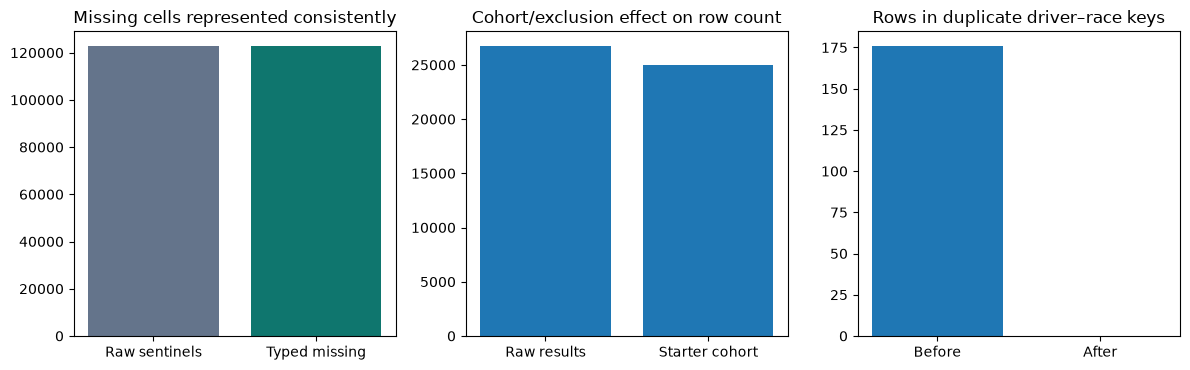

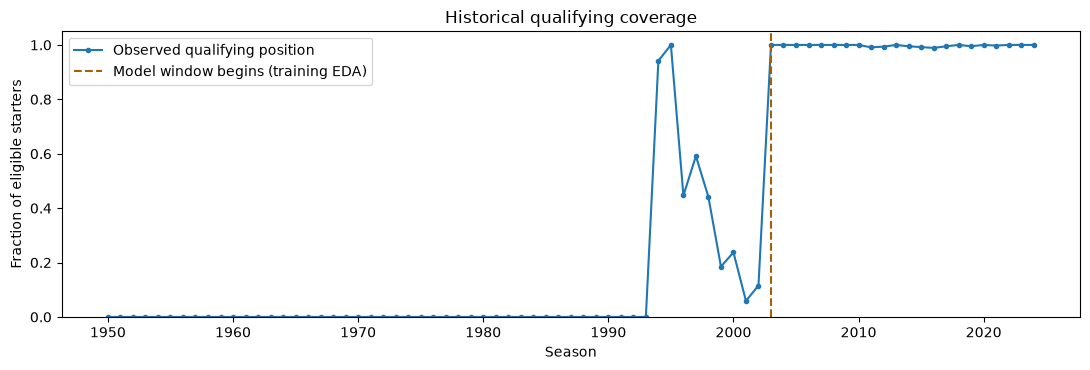

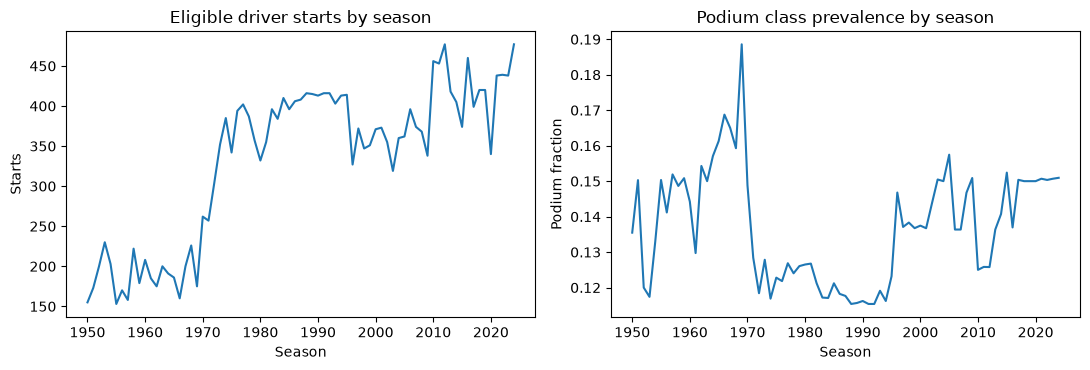

In [5]:
clean = clean_data(raw, OUT)
cohort, ordered_races, cohort_summary = build_cohort(clean, OUT)
coverage = exploratory_analysis(raw, clean, cohort, OUT)

## 5. Feature engineering and chronological split

Training-only coverage motivates 2003 as the model-window start. Split 2003–2019 / 2020–2021 / reserved 2022–2024. Lag driver and constructor form and as-of join strictly earlier within-season standings. Encode IDs as categories; never use current-race outcomes. Feature evidence is training-only.

In [6]:
def add_prior_standings(frame, standings, races, entity, prefix):
    """As-of join strictly earlier main-race standings, reset within each season."""
    history = standings.merge(races[['raceId','year','event_idx']],on='raceId',validate='many_to_one')
    history = history.rename(columns={'event_idx':prefix+'_source_event','points':prefix+'_points_before',
                                     'position':prefix+'_rank_before'})
    cols = [entity,'year',prefix+'_source_event',prefix+'_points_before',prefix+'_rank_before']
    history = history[cols].sort_values(prefix+'_source_event')
    result = pd.merge_asof(frame.sort_values('event_idx'),history,left_on='event_idx',
        right_on=prefix+'_source_event',by=[entity,'year'],direction='backward',allow_exact_matches=False)
    ok = result[prefix+'_source_event'].notna()
    assert (result.loc[ok,prefix+'_source_event'] < result.loc[ok,'event_idx']).all()
    # Zero points is safe only when no earlier record exists for that entrant this season.
    result.loc[~ok,prefix+'_points_before'] = 0.0
    return result.sort_values(['event_idx','driverId']).reset_index(drop=True)


def engineer_features(cohort, clean, races, out):
    f = cohort.copy()
    q = clean['qualifying'].copy()
    q['q1_gap_to_best'] = q.q1_seconds-q.groupby('raceId').q1_seconds.transform('min')
    q = q[KEY+['position','q1_gap_to_best']].rename(columns={'position':'qualifying_position'})
    f = f.merge(q,on=KEY,how='left',validate='one_to_one').sort_values(['event_idx','driverId'])
    f['driver_form_podium_last5'] = f.groupby('driverId').podium.transform(lambda s:s.shift().rolling(5,min_periods=1).mean())
    f['driver_form_finish_last5'] = f.groupby('driverId').positionOrder.transform(lambda s:s.shift().rolling(5,min_periods=1).mean())
    f['driver_form_source_event'] = f.groupby('driverId').event_idx.shift()
    history = f.groupby(['constructorId','raceId','event_idx'],as_index=False).agg(team_race_podium_rate=('podium','mean'))
    history = history.sort_values('event_idx')
    history['constructor_form_podium_last5'] = history.groupby('constructorId').team_race_podium_rate.transform(lambda s:s.shift().rolling(5,min_periods=1).mean())
    history['constructor_form_source_event'] = history.groupby('constructorId').event_idx.shift()
    f = f.merge(history[['constructorId','raceId','constructor_form_podium_last5','constructor_form_source_event']],
                on=['constructorId','raceId'],validate='many_to_one')
    for source in ['driver_form_source_event','constructor_form_source_event']:
        valid = f[source].notna()
        assert (f.loc[valid,source] < f.loc[valid,'event_idx']).all()
    f = add_prior_standings(f,clean['driver_standings'],races,'driverId','driver_standings')
    f = add_prior_standings(f,clean['constructor_standings'],races,'constructorId','constructor_standings')
    # Modeling window chosen from training-only qualifying coverage; history still includes earlier races.
    model = f.loc[f.year.between(2003,2024)].copy().reset_index(drop=True)
    numeric = ['grid_position','grid_zero_flag','qualifying_position','q1_gap_to_best',
        'driver_form_podium_last5','driver_form_finish_last5','constructor_form_podium_last5',
        'driver_standings_points_before','driver_standings_rank_before',
        'constructor_standings_points_before','constructor_standings_rank_before','round']
    categorical = ['constructorId','circuitId']
    features = numeric+categorical
    for c in numeric: model[c] = pd.to_numeric(model[c],errors='coerce').astype(float)
    for c in categorical: model[c] = model[c].astype(int).astype(str)
    model['split'] = np.select([model.year.le(2019),model.year.between(2020,2021)],['train','validation'],default='test_reserved')
    assert not model.duplicated(KEY).any()
    groups = model.groupby('split').agg(rows=('podium','size'),races=('raceId','nunique'),start_year=('year','min'),end_year=('year','max'))
    groups.to_csv(Path(out)/'split_summary.csv')
    race_sets = [set(model.loc[model.split.eq(s),'raceId']) for s in ['train','validation','test_reserved']]
    assert all(not race_sets[i]&race_sets[j] for i in range(3) for j in range(i+1,3))
    assert not set(features)&{'podium','positionOrder','statusId','points','laps','milliseconds','rank','fastestLapTime'}
    model[KEY+['year','split','podium']+features].to_csv(Path(out)/'modeling_table.csv',index=False)
    model[KEY+['event_idx','driver_form_source_event','constructor_form_source_event',
        'driver_standings_source_event','constructor_standings_source_event']].to_csv(Path(out)/'feature_lineage.csv',index=False)
    specs = {
      'grid_position':('grid','results.grid','Actual positive starting position after penalties; zero represented separately.'),
      'grid_zero_flag':('grid','results.grid','Zero-grid indicator; never interpret zero as better than pole.'),
      'qualifying_position':('qualifying','qualifying.position','Qualifying rank available after session; not equivalent to grid.'),
      'q1_gap_to_best':('qualifying','qualifying.q1','Seconds behind fastest recorded Q1 at same race; session-normalized.'),
      'driver_form_podium_last5':('form','earlier results','Mean podium label over up to five earlier starts, shifted first.'),
      'driver_form_finish_last5':('form','earlier results','Mean positionOrder over up to five earlier starts, shifted first.'),
      'constructor_form_podium_last5':('form','earlier results','Mean of team per-race podium rates over up to five earlier races; constructorId history.'),
      'driver_standings_points_before':('standings','driver_standings + races','Most recent strictly earlier race within same season; zero before first record.'),
      'driver_standings_rank_before':('standings','driver_standings + races','Most recent strictly earlier rank this season; missing before first record.'),
      'constructor_standings_points_before':('standings','constructor_standings + races','Most recent strictly earlier constructor points in season; zero before first record.'),
      'constructor_standings_rank_before':('standings','constructor_standings + races','Most recent strictly earlier constructor rank in season; missing before first record.'),
      'round':('context','races.round','Known scheduled championship round; context for season progress.'),
      'constructorId':('identity','results.constructorId','Pre-race entrant team identity; categorical, not an ordinal number.'),
      'circuitId':('context','races.circuitId','Known circuit identity; categorical, not an ordinal number.')}
    train = model.loc[model.split.eq('train')]
    evidence = []
    for c in features:
        group, source, meaning = specs[c]
        correlation = train[c].corr(train.podium,method='spearman') if c in numeric and train[c].nunique()>1 else np.nan
        evidence.append({'feature':c,'group':group,'source':source,'pre_race_validity':meaning,
                         'training_missing_fraction':train[c].isna().mean(),'training_spearman_with_podium':correlation,
                         'evidence':'04_feature_evidence.png (training only); group ablation pending batch 2'})
    registry = pd.DataFrame(evidence)
    registry.to_csv(Path(out)/'feature_register.csv',index=False)
    fig, axes = plt.subplots(4,4,figsize=(15,13))
    for ax,c in zip(axes.ravel(),features):
        if c in numeric and train[c].nunique()>8:
            bins = pd.qcut(train[c],5,duplicates='drop')
            rates = train.groupby(bins,observed=True).podium.agg(['mean','size'])
        else:
            rates = train.groupby(c,observed=True).podium.agg(['mean','size']).sort_values('size',ascending=False).head(10)
        ax.bar(np.arange(len(rates)),rates['mean'])
        ax.set_xticks(np.arange(len(rates)),[str(v) for v in rates.index],rotation=65,ha='right',fontsize=7)
        ax.set(title=c,ylabel='Training podium rate',ylim=(0,1))
    for ax in axes.ravel()[len(features):]: ax.axis('off')
    save_figure(fig,out,'04_feature_evidence')
    print(groups.to_string())
    return model, numeric, categorical, registry


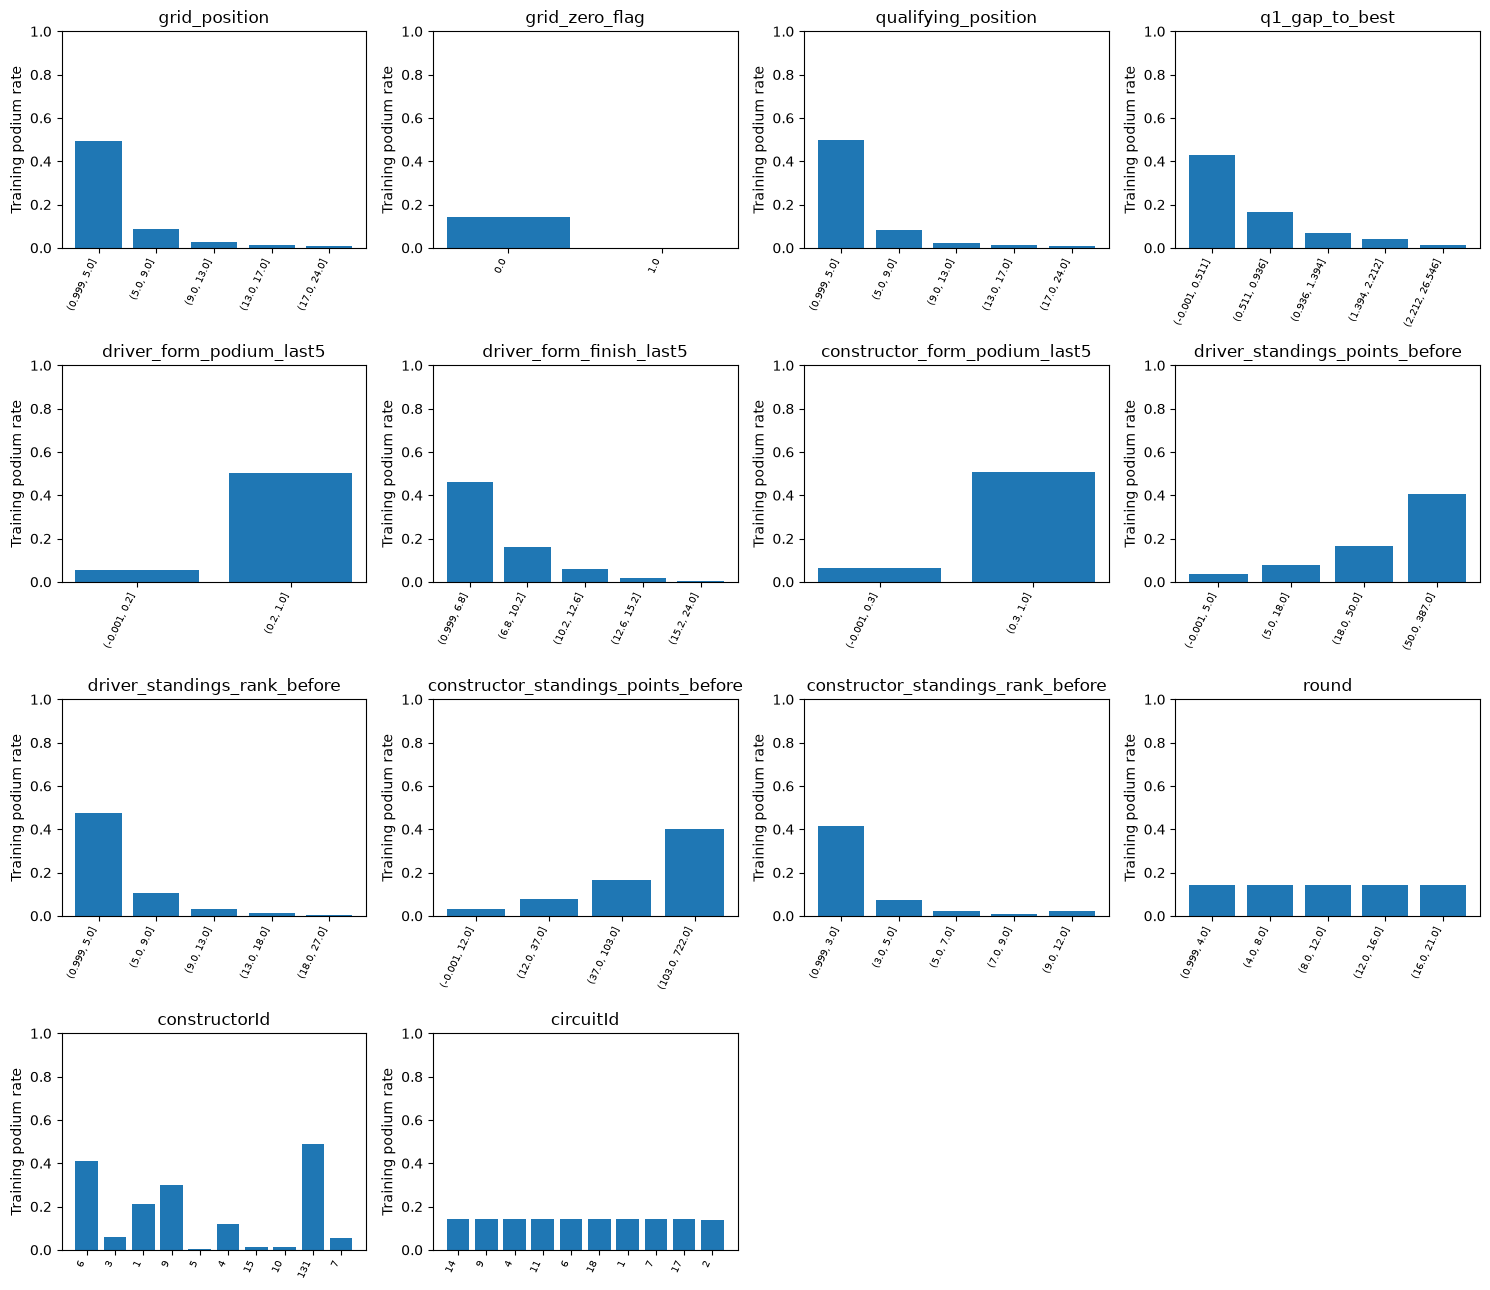

               rows  races  start_year  end_year
split                                           
test_reserved  1354     68        2022      2024
train          6799    321        2003      2019
validation      778     39        2020      2021


,feature,group,source,pre_race_validity,training_missing_fraction,training_spearman_with_podium,evidence
0,grid_position,grid,results.grid,Actual positive starting position after penalt...,0.002795,-0.494365,04_feature_evidence.png (training only); group...
1,grid_zero_flag,grid,results.grid,Zero-grid indicator; never interpret zero as b...,0.000000,-0.021504,04_feature_evidence.png (training only); group...
2,qualifying_position,qualifying,qualifying.position,Qualifying rank available after session; not e...,0.003089,-0.496695,04_feature_evidence.png (training only); group...
3,q1_gap_to_best,qualifying,qualifying.q1,Seconds behind fastest recorded Q1 at same rac...,0.018091,-0.397238,04_feature_evidence.png (training only); group...
4,driver_form_podium_last5,form,earlier results,Mean podium label over up to five earlier star...,0.011031,0.526783,04_feature_evidence.png (training only); group...
5,driver_form_finish_last5,form,earlier results,Mean positionOrder over up to five earlier sta...,0.011031,-0.443184,04_feature_evidence.png (training only); group...
6,constructor_form_podium_last5,form,earlier results,Mean of team per-race podium rates over up to ...,0.005148,0.514755,04_feature_evidence.png (training only); group...
7,driver_standings_points_before,standings,driver_standings + races,Most recent strictly earlier race within same ...,0.000000,0.370604,04_feature_evidence.png (training only); group...
8,driver_standings_rank_before,standings,driver_standings + races,Most recent strictly earlier rank this season;...,0.071334,-0.477805,04_feature_evidence.png (training only); group...
9,constructor_standings_points_before,standings,constructor_standings + races,Most recent strictly earlier constructor point...,0.000000,0.362412,04_feature_evidence.png (training only); group...


In [7]:
model, numeric_features, categorical_features, feature_register = engineer_features(cohort, clean, ordered_races, OUT)
display(feature_register)

## 6. Front-row conversion before and from 2014

Join results → races → circuits and qualifying. Actual grid 1/2 defines front row; denominator is front-row starts. Use 1950–2013 vs 2014–2024, excluding Indianapolis. Save all circuits; the plot displays circuits with at least 10 starts to expose small-sample issues.

In [8]:
def question_front_row(cohort, clean, out):
    a = cohort.loc[~cohort.name.str.contains('Indianapolis',case=False)].merge(
        clean['circuits'][['circuitId','name']].rename(columns={'name':'circuit_name'}),
        on='circuitId',validate='many_to_one')
    a = a.merge(clean['qualifying'][KEY+['position']].rename(columns={'position':'qualifying_position'}),
                on=KEY,how='left',validate='one_to_one')
    a['era'] = np.where(a.year.lt(2014),'1950–2013','2014–2024')
    result = a.loc[a.grid.isin([1,2])].groupby(['circuitId','circuit_name','era']).podium.agg(starts='size',podiums='sum',rate='mean').reset_index()
    result['rank_within_era'] = result.groupby('era').rate.rank(method='min',ascending=False)
    result = result.sort_values(['era','rate','starts'],ascending=[True,False,False])
    result.to_csv(Path(out)/'q1_front_row_rates.csv',index=False)
    paired = result.pivot(index='circuit_name',columns='era',values='rate').dropna()
    paired['change'] = paired['2014–2024']-paired['1950–2013']
    paired.to_csv(Path(out)/'q1_circuit_changes.csv')
    compar = a.loc[a.qualifying_position.notna()]
    distinction = {'qualifying_rows':len(compar),
        'qualifying_grid_disagreements':int(compar.qualifying_position.ne(compar.grid).sum()),
        'front_row_qualifying_not_grid':int((compar.qualifying_position.isin([1,2])&~compar.grid.isin([1,2])).sum()),
        'Indianapolis_excluded':True}
    write_json(Path(out)/'q1_definitions.json',distinction)
    fig, axes = plt.subplots(1,2,figsize=(13,5.5))
    for ax,era in zip(axes,['1950–2013','2014–2024']):
        shown = result.loc[(result.era==era)&(result.starts>=10)].head(10).sort_values('rate')
        ax.barh(shown.circuit_name,shown.rate,color='#0f766e')
        ax.set(xlim=(0,1.07),xlabel='Podiums / front-row starts',title=era+' (at least 10 starts)')
        for i,(_,r) in enumerate(shown.iterrows()): ax.text(r.rate+.01,i,f'{r.podiums}/{r.starts}',va='center',fontsize=8)
    save_figure(fig,out,'05_front_row_by_era')
    print(result.groupby('era').head(5).to_string(index=False))
    return result, paired, distinction


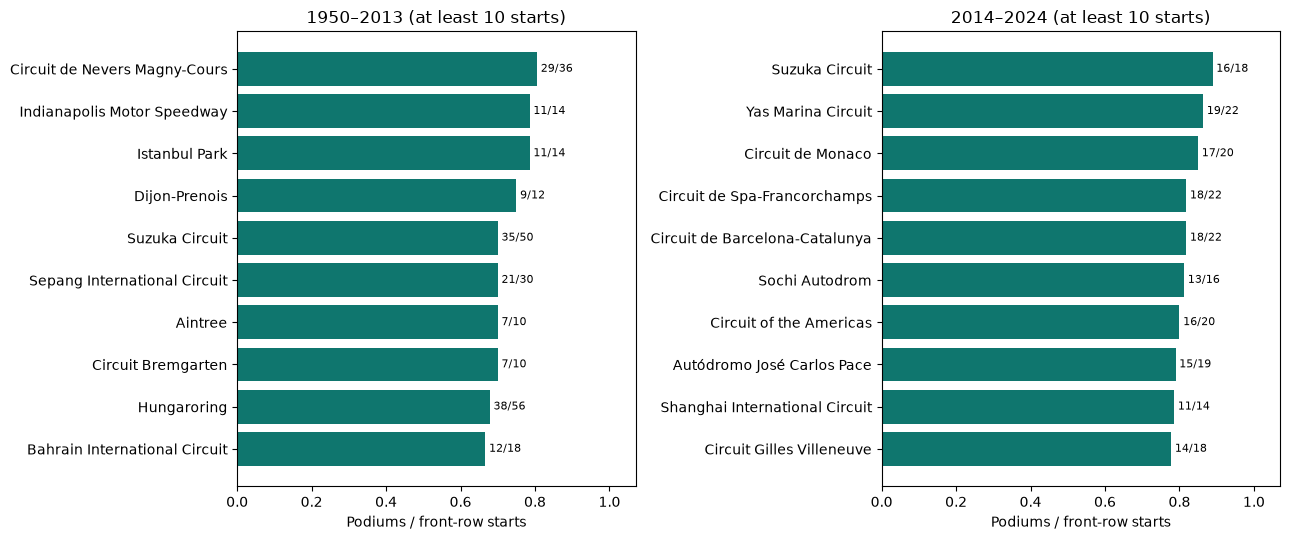

 circuitId                         circuit_name       era  starts  podiums     rate  rank_within_era
        69              Circuit of the Americas 1950–2013       4        4 1.000000              1.0
        31                       Donington Park 1950–2013       2        2 1.000000              1.0
        64                             Ain Diab 1950–2013       2        2 1.000000              1.0
        65                      Pescara Circuit 1950–2013       2        2 1.000000              1.0
        68          Buddh International Circuit 1950–2013       6        5 0.833333              5.0
        79        Miami International Autodrome 2014–2024       6        6 1.000000              1.0
        75   Autódromo Internacional do Algarve 2014–2024       4        4 1.000000              1.0
        80       Las Vegas Strip Street Circuit 2014–2024       4        4 1.000000              1.0
        76 Autodromo Internazionale del Mugello 2014–2024       2        2 1.000000        

era,1950–2013,2014–2024,change
circuit_name,,,
Circuit de Monaco,0.491667,0.850000,0.358333
Circuit Park Zandvoort,0.583333,0.875000,0.291667
Circuit de Spa-Francorchamps,0.538462,0.818182,0.279720
Yas Marina Circuit,0.600000,0.863636,0.263636
Autodromo Nazionale di Monza,0.468750,0.727273,0.258523
Circuit Gilles Villeneuve,0.529412,0.777778,0.248366
Red Bull Ring,0.520000,0.730769,0.210769
Autódromo José Carlos Pace,0.596774,0.789474,0.192699
Suzuka Circuit,0.700000,0.888889,0.188889


In [9]:
front_row_rates, circuit_changes, front_row_definitions = question_front_row(cohort, clean, OUT)
display(circuit_changes.sort_values("change",ascending=False).head(10))

## 7. Home-race effect controlling starting grid

Join drivers and circuits through results/races. Map nationality to country explicitly; withhold ambiguous dual nationality. Standardize home/away outcomes to the same pooled grid-stratum distribution on common support. This controls grid coarsely and is not a causal analysis.

In [10]:
def question_home(cohort, clean, out):
    a = cohort.loc[~cohort.name.str.contains('Indianapolis',case=False)].merge(
        clean['drivers'][['driverId','nationality']],on='driverId',validate='many_to_one').merge(
        clean['circuits'][['circuitId','country']],on='circuitId',validate='many_to_one')
    a['home_country'] = a.nationality.str.strip().map(COUNTRY)
    a['country'] = a.country.replace({'United States':'USA'})
    a['mapping_known'] = a.home_country.notna()
    a.loc[~a.mapping_known,['driverId','nationality']].drop_duplicates().to_csv(Path(out)/'q2_unmapped_nationalities.csv',index=False)
    mapping = a[['nationality','home_country']].drop_duplicates().sort_values('nationality')
    mapping.to_csv(Path(out)/'q2_country_mapping.csv',index=False)
    eligible = a.loc[a.mapping_known & a.grid.gt(0)].copy()
    eligible['home'] = eligible.home_country.eq(eligible.country)
    eligible['grid_stratum'] = pd.cut(eligible.grid,bins=[0,2,5,10,15,np.inf],labels=['1–2','3–5','6–10','11–15','16+'])
    grouped = eligible.groupby(['grid_stratum','home'],observed=True).podium.agg(starts='size',podiums='sum',rate='mean').reset_index()
    grouped.to_csv(Path(out)/'q2_grid_strata.csv',index=False)
    rate = grouped.pivot(index='grid_stratum',columns='home',values='rate').dropna()
    counts = grouped.pivot(index='grid_stratum',columns='home',values='starts').loc[rate.index]
    weights = counts.sum(axis=1)/counts.sum().sum()
    adjusted = (rate.mul(weights,axis=0)).sum()
    raw_rates = eligible.groupby('home').podium.mean()
    summary = pd.DataFrame({'group':['Away','Home'],
        'raw_podium_rate':[raw_rates[False],raw_rates[True]],
        'grid_standardized_rate':[adjusted[False],adjusted[True]]})
    summary.to_csv(Path(out)/'q2_home_summary.csv',index=False)
    weights.rename('common_grid_weight').to_csv(Path(out)/'q2_standardization_weights.csv')
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    rate.rename(columns={False:'Away',True:'Home'}).plot.bar(ax=axes[0],rot=0)
    axes[0].set(title='Podium rates within starting-grid strata',ylabel='Podium fraction',xlabel='Starting grid')
    axes[1].bar(summary.group,summary.grid_standardized_rate,color=['#64748b','#0f766e'])
    axes[1].set(title='Same grid distribution for home and away',ylabel='Standardized podium fraction')
    save_figure(fig,out,'06_home_grid_control')
    exclusions = {'unmapped_driver_rows':int((~a.mapping_known).sum()),
        'mapped_rows_without_positive_grid':int((a.mapping_known & ~a.grid.gt(0)).sum()),
        'eligible_rows':len(eligible),'strata_with_common_support':list(map(str,rate.index)),
        'limitation':'Grid strata retain within-bin differences; driver, constructor, circuit and era confounding remain. Not a causal effect. Dual nationalities excluded rather than guessed.'}
    write_json(Path(out)/'q2_definitions.json',exclusions)
    print(summary.to_string(index=False))
    return summary, grouped, exclusions


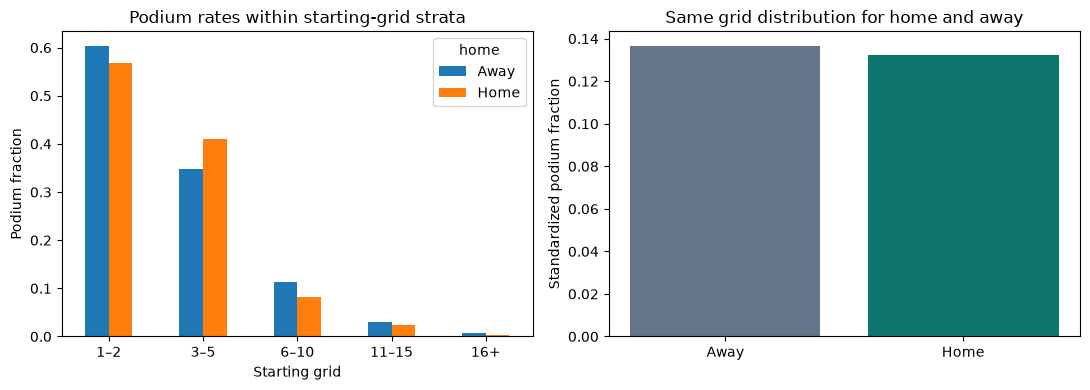

group  raw_podium_rate  grid_standardized_rate
 Away         0.137856                0.136625
 Home         0.116580                0.132107


,grid_stratum,home,starts,podiums,rate
0,1–2,False,2064,1246,0.603682
1,1–2,True,160,91,0.568750
2,3–5,False,3129,1091,0.348674
3,3–5,True,215,88,0.409302
4,6–10,False,5127,577,0.112541
5,6–10,True,414,34,0.082126
6,11–15,False,5110,152,0.029746
7,11–15,True,414,10,0.024155
8,16+,False,7195,53,0.007366
9,16+,True,727,2,0.002751


In [11]:
home_summary, home_strata, home_definitions = question_home(cohort, clean, OUT)
display(home_strata)

## 8. Mechanical retirements by constructor

Join results → races/status/constructors. Compare 2014–2021 vs 2022–2024 per constructorId. Divide documented mechanical retirements by driver-starts. Exclude accidents, driver and regulatory causes; show ambiguous statuses separately rather than labeling all DNF as mechanical.

In [12]:
def question_mechanical(cohort, clean, out):
    def classify(status):
        if status in MECHANICAL: return 'mechanical'
        if status=='Finished' or status.startswith('+'): return 'finished'
        if status in ACCIDENT_DRIVER_REG: return 'accident_driver_regulation'
        if status in ['Did not qualify','Did not prequalify','107% Rule','Withdrew','Excluded']: return 'non_start_or_exclusion'
        return 'ambiguous_or_other'
    mapping = clean['status'].copy()
    mapping['group'] = mapping.status.map(classify)
    mapping['rule'] = np.where(mapping.group.eq('mechanical'),'Explicit component failure / mechanical system; conservative mapping',
                              'Not counted as a proven mechanical failure')
    mapping.to_csv(Path(out)/'q3_status_mapping.csv',index=False)
    a = cohort.loc[cohort.year.between(2014,2024)].merge(
        clean['constructors'][['constructorId','name']].rename(columns={'name':'constructor_name'}),
        on='constructorId',validate='many_to_one')
    a['mechanical'] = a.status_text.isin(MECHANICAL).astype(int)
    a['ambiguous'] = a.status_text.map(classify).eq('ambiguous_or_other').astype(int)
    a['period'] = np.where(a.year.le(2021),'2014–2021','2022–2024')
    summary = a.groupby(['constructorId','constructor_name','period']).agg(
        starts=('mechanical','size'),mechanical_retirements=('mechanical','sum'),ambiguous_statuses=('ambiguous','sum')).reset_index()
    summary['mechanical_rate'] = summary.mechanical_retirements/summary.starts
    summary = summary.sort_values(['period','mechanical_rate','starts'],ascending=[True,False,False])
    summary.to_csv(Path(out)/'q3_mechanical_rates.csv',index=False)
    a.loc[a.ambiguous.eq(1)].groupby(['period','status_text']).size().rename('count').to_csv(Path(out)/'q3_ambiguous_status_counts.csv')
    fig, axes = plt.subplots(1,2,figsize=(13,5.5))
    for ax,period in zip(axes,['2014–2021','2022–2024']):
        shown = summary.loc[summary.period.eq(period)].sort_values('mechanical_rate')
        ax.barh(shown.constructor_name,shown.mechanical_rate,color='#0f766e')
        ax.set(xlabel='Mechanical retirements / constructor starts',title=period)
        for i,(_,r) in enumerate(shown.iterrows()): ax.text(r.mechanical_rate+.002,i,f'{r.mechanical_retirements}/{r.starts}',va='center',fontsize=8)
        ax.set_xlim(0,max(shown.mechanical_rate)*1.3+.01)
    save_figure(fig,out,'07_mechanical_retirements')
    print(summary.groupby('period').head(5).to_string(index=False))
    return summary, mapping


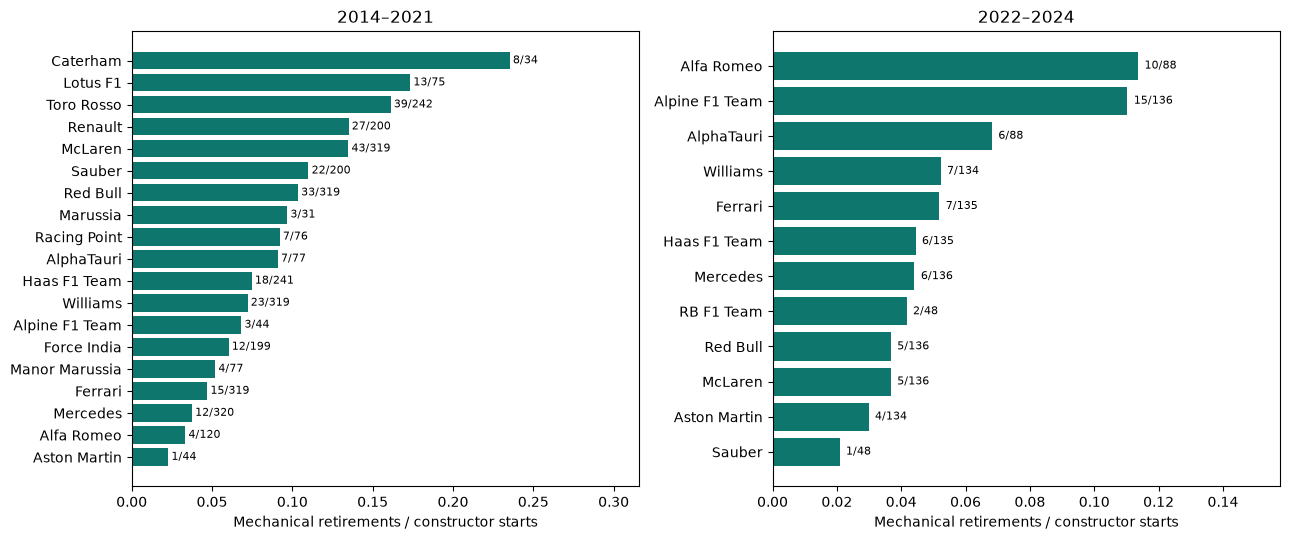

 constructorId constructor_name    period  starts  mechanical_retirements  ambiguous_statuses  mechanical_rate
           207         Caterham 2014–2021      34                       8                   3         0.235294
           208         Lotus F1 2014–2021      75                      13                   5         0.173333
             5       Toro Rosso 2014–2021     242                      39                   5         0.161157
             4          Renault 2014–2021     200                      27                   6         0.135000
             1          McLaren 2014–2021     319                      43                   8         0.134796
            51       Alfa Romeo 2022–2024      88                      10                   1         0.113636
           214   Alpine F1 Team 2022–2024     136                      15                   0         0.110294
           213       AlphaTauri 2022–2024      88                       6                   1         0.068182
 

,statusId,status,group,rule
0,1,Finished,finished,Not counted as a proven mechanical failure
1,2,Disqualified,accident_driver_regulation,Not counted as a proven mechanical failure
2,3,Accident,accident_driver_regulation,Not counted as a proven mechanical failure
3,4,Collision,accident_driver_regulation,Not counted as a proven mechanical failure
4,5,Engine,mechanical,Explicit component failure / mechanical system...
...,...,...,...,...
134,137,Damage,ambiguous_or_other,Not counted as a proven mechanical failure
135,138,Debris,ambiguous_or_other,Not counted as a proven mechanical failure
136,139,Illness,accident_driver_regulation,Not counted as a proven mechanical failure
137,140,Undertray,ambiguous_or_other,Not counted as a proven mechanical failure


In [13]:
mechanical_rates, status_mapping = question_mechanical(cohort, clean, OUT)
display(status_mapping)

## 9–10. Logistic regression and random forest

Use identical rows and features with train-only fitted preprocessing. Logistic regression is the baseline. Select hyperparameters by validation average precision (AP); select thresholds by validation F1. Report trapezoidal PR-AUC and AP separately. Do not evaluate the reserved test yet: freeze choices after the remaining models/experiments.

In [14]:
def make_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
                             ('scale',StandardScaler())]),numeric),
        ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical)],
        sparse_threshold=0)


def metrics(y, probabilities, threshold):
    pred = probabilities>=threshold
    precision, recall, _ = precision_recall_curve(y,probabilities)
    return {'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
        'recall':recall_score(y,pred,zero_division=0),'F1':f1_score(y,pred,zero_division=0),
        'ROC_AUC':roc_auc_score(y,probabilities),'PR_AUC':auc(recall,precision),
        'average_precision':average_precision_score(y,probabilities)}


def train_statistical_models(model, numeric, categorical, out):
    """No test labels, predictions, scores or plots are used in this batch."""
    features = numeric+categorical
    train = model.loc[model.split.eq('train')]
    val = model.loc[model.split.eq('validation')]
    Xtr, Xval = train[features],val[features]
    ytr, yval = train.podium,val.podium
    candidates = [('Logistic regression',{'C':c},LogisticRegression(C=c,max_iter=3000,random_state=SEED)) for c in [0.1,1.0,10.0]]
    candidates += [('Random forest',{'max_depth':d,'min_samples_leaf':3,'n_estimators':250},
        RandomForestClassifier(n_estimators=250,max_depth=d,min_samples_leaf=3,random_state=SEED,n_jobs=2)) for d in [6,12]]
    trials, fitted = [], {}
    for name,params,estimator in candidates:
        pipe = Pipeline([('preprocess',make_preprocessor(numeric,categorical)),('model',estimator)])
        pipe.fit(Xtr,ytr)
        p = pipe.predict_proba(Xval)[:,1]
        score = average_precision_score(yval,p)
        trials.append({'model':name,'parameters':json.dumps(params),'validation_AP':score})
        if name not in fitted or score > fitted[name]['validation_AP']:
            fitted[name] = {'pipeline':pipe,'parameters':params,'validation_AP':score}
    trials = pd.DataFrame(trials)
    trials.to_csv(Path(out)/'statistical_model_trials.csv',index=False)
    results, thresholds, predictions = [], {}, []
    fig, axes = plt.subplots(1,2,figsize=(11,4.2))
    for name,info in fitted.items():
        pipe = info['pipeline']
        p = pipe.predict_proba(Xval)[:,1]
        search = pd.DataFrame({'threshold':np.linspace(.05,.95,91)})
        search['F1'] = [f1_score(yval,p>=t,zero_division=0) for t in search.threshold]
        # Stable tie break: prefer threshold closest to 0.5, then lower threshold.
        search['distance_to_half'] = abs(search.threshold-.5)
        best = search.sort_values(['F1','distance_to_half','threshold'],ascending=[False,True,True]).iloc[0]
        threshold = float(best.threshold)
        info['threshold'] = threshold
        thresholds[name] = {'threshold':threshold,'parameters':info['parameters']}
        search.to_csv(Path(out)/(name.lower().replace(' ','_')+'_threshold_search.csv'),index=False)
        for split,frame in [('train',train),('validation',val)]:
            probability = pipe.predict_proba(frame[features])[:,1]
            results.append({'model':name,'split':split,'threshold':threshold,**metrics(frame.podium,probability,threshold)})
        predictions.append(val[KEY+['podium']].assign(model=name,probability=p))
        RocCurveDisplay.from_predictions(yval,p,name=name,ax=axes[0])
        PrecisionRecallDisplay.from_predictions(yval,p,name=name,ax=axes[1])
        joblib.dump(pipe,Path(out)/(name.lower().replace(' ','_')+'.joblib'))
        fig_cm,ax_cm = plt.subplots(figsize=(4,3.5))
        ConfusionMatrixDisplay.from_predictions(yval,p>=threshold,ax=ax_cm,display_labels=['Not podium','Podium'],colorbar=False)
        ax_cm.set_title(name+' — validation')
        save_figure(fig_cm,out,name.lower().replace(' ','_')+'_confusion')
    axes[0].set_title('Validation ROC curves')
    axes[1].axhline(yval.mean(),color='#64748b',linestyle='--',label='Class prevalence')
    axes[1].set_title('Validation precision–recall curves')
    axes[1].legend()
    save_figure(fig,out,'08_statistical_model_curves')
    results = pd.DataFrame(results)
    results.to_csv(Path(out)/'statistical_model_metrics.csv',index=False)
    pd.concat(predictions,ignore_index=True).to_csv(Path(out)/'validation_predictions.csv',index=False)
    write_json(Path(out)/'selected_statistical_models.json',thresholds)
    names = [tuple(i['pipeline'].named_steps['preprocess'].get_feature_names_out()) for i in fitted.values()]
    assert names[0]==names[1], 'Both models must see exactly the same encoded features.'
    write_json(Path(out)/'model_feature_contract.json',{'input_features':features,'encoded_features':names[0],
        'train_keys_sha256':hashlib.sha256(train[KEY].to_csv(index=False).encode()).hexdigest(),
        'validation_keys_sha256':hashlib.sha256(val[KEY].to_csv(index=False).encode()).hexdigest(),
        'primary_metric':'Average precision (AP), explicitly distinct from trapezoidal PR-AUC',
        'secondary_metrics':['PR_AUC','F1','ROC_AUC'],'test_evaluated':False})
    print(results.to_string(index=False))
    return fitted, results, trials


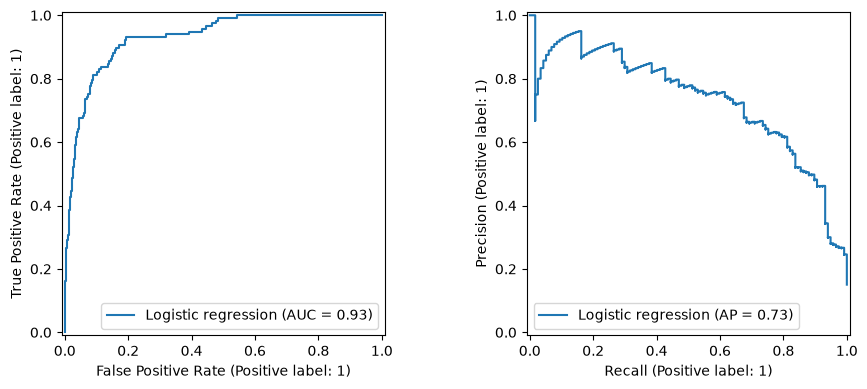

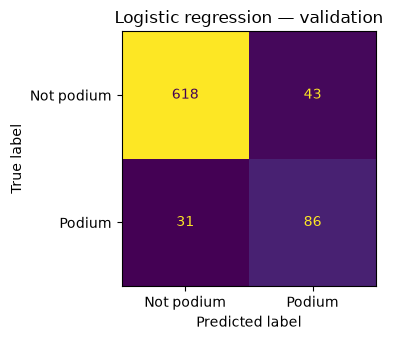

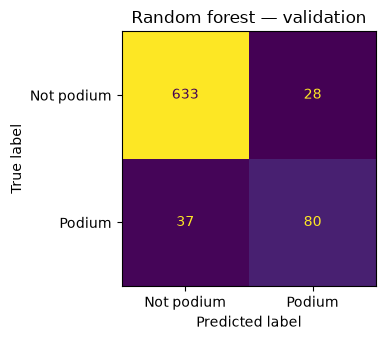

              model      split  threshold  accuracy  precision   recall       F1  ROC_AUC   PR_AUC  average_precision
Logistic regression      train       0.33  0.894249   0.597600 0.775701 0.675102 0.932443 0.689749           0.690305
Logistic regression validation       0.33  0.904884   0.666667 0.735043 0.699187 0.931146 0.730846           0.733270
      Random forest      train       0.49  0.933961   0.808894 0.698858 0.749861 0.973038 0.866440           0.866513
      Random forest validation       0.49  0.916452   0.740741 0.683761 0.711111 0.930589 0.738035           0.739633


,model,parameters,validation_AP
0,Logistic regression,"{""C"": 0.1}",0.731677
1,Logistic regression,"{""C"": 1.0}",0.733270
2,Logistic regression,"{""C"": 10.0}",0.732011
3,Random forest,"{""max_depth"": 6, ""min_samples_leaf"": 3, ""n_est...",0.727584
4,Random forest,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""n_es...",0.739633


,model,split,threshold,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,average_precision
0,Logistic regression,train,0.33,0.894249,0.597600,0.775701,0.675102,0.932443,0.689749,0.690305
1,Logistic regression,validation,0.33,0.904884,0.666667,0.735043,0.699187,0.931146,0.730846,0.733270
2,Random forest,train,0.49,0.933961,0.808894,0.698858,0.749861,0.973038,0.866440,0.866513
3,Random forest,validation,0.49,0.916452,0.740741,0.683761,0.711111,0.930589,0.738035,0.739633


In [15]:
statistical_models, model_metrics, model_trials = train_statistical_models(model, numeric_features, categorical_features, OUT)
display(model_trials)
display(model_metrics)

## Batch 1 interpretation and report section

The following report is generated from this run’s evidence. It is a draft for the first batch, not a completed submission.

In [16]:
def verify_raw_unchanged(data_dir, hashes):
    assert all(file_hash(Path(data_dir)/f'{name}.csv')==digest for name,digest in hashes.items())
    print('PASS: all 14 raw CSV hashes unchanged.')


In [17]:
"""Generate the report section from measured results, never placeholder findings."""
from pathlib import Path
import json
import pandas as pd

def write_batch1_report(out, destination):
    out, destination = Path(out), Path(destination)
    def read(name): return pd.read_csv(out/name)
    def table(frame):
        def fmt(v):
            if pd.isna(v): return '—'
            if isinstance(v,float): return f'{v:.4f}'
            return str(v).replace('|','/')
        return '\n'.join(['| '+' | '.join(frame.columns)+' |','| '+' | '.join(['---']*len(frame.columns))+' |']+
            ['| '+' | '.join(map(fmt,r))+' |' for r in frame.itertuples(index=False,name=None)])
    def figure(name,caption):
        # Relative links resolve from reports/ to the local run outputs.
        return f'![{caption}](../outputs/batch1/figures/{name}.png)\n\n{caption}'
    inventory = read('table_inventory.csv')
    cohort = json.loads((out/'cohort_summary.json').read_text())
    q1 = read('q1_front_row_rates.csv')
    q1_supported = q1.loc[q1.starts.ge(10)]
    top1 = q1_supported.groupby('era').head(3)
    ranks = q1.pivot(index='circuit_name',columns='era',values='rank_within_era').dropna()
    changed = int(ranks.iloc[:,0].ne(ranks.iloc[:,1]).sum())
    q2 = read('q2_home_summary.csv')
    q2def = json.loads((out/'q2_definitions.json').read_text())
    q3 = read('q3_mechanical_rates.csv')
    metrics = read('statistical_model_metrics.csv')
    registry = read('feature_register.csv')
    primary = metrics.loc[metrics.split.eq('validation')].sort_values('average_precision',ascending=False).iloc[0]
    home = q2.set_index('group').loc['Home','grid_standardized_rate']
    away = q2.set_index('group').loc['Away','grid_standardized_rate']
    lines = [
      '# ACL Milestone 1 — batch 1 report draft (work packages 1–10)',
      '',
      '**Status:** reproducible first batch, not the final milestone submission. Shallow NN, ablation, preprocessing-order experiments, XAI, inference demonstrations, final test scores, team review, and final PDF remain for later batches.',
      '',
      '## Objective and scope',
      'Predict whether an eligible race starter finishes on the podium using information available after qualifying and before the main race. The binary label is positionOrder ≤ 3; exact finishing-position prediction is outside scope. Descriptive questions use historical outcomes, but those current-race outcomes never enter the predictor whitelist.',
      '',
      '## Source and audit',
      'Source: [the assignment-cited Kaggle/Ergast dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020). The downloaded snapshot contains all 14 tables and results for all 24 races in 2024. Source_manifest.json records per-file SHA-256 and runtime versions. Every run checks that raw hashes are unchanged.',
      '',table(inventory),
      '',
      'Implemented candidate-key checks found no null/duplicate primary keys; the documented foreign-key checks found no orphan values. Per-column schemas and missingness are in column_inventory.csv and each tested relationship is in foreign_key_checks.csv. These checks establish properties of this snapshot, not externally enforced database constraints.',
      '',
      '## Cleaning, cohort and duplicate rule',
      'Cleaning replaces literal backslash-N and blank tokens with actual missing values on working copies. Numeric columns, dates, and qualifying/lap/pit-stop durations receive semantic types; duration values are also represented in seconds. Conversion failures are counted and must be zero. Missing Q2/Q3 can be structural non-advancement; the baseline does not impute these as if every driver participated.',
      '',
      f"Raw results: {cohort['raw_result_rows']:,} rows. Non-qualifier exclusions: {cohort['excluded_non_qualifiers']:,}; documented non-start exclusions: {cohort['excluded_documented_non_starts']:,}; uncertain zero-grid/zero-lap entries withheld: {cohort['ambiguous_starts_withheld']:,}. Duplicate rows removed after eligibility filtering: {cohort['duplicate_rows_removed']:,}. Final historical cohort: {cohort['eligible_driver_race_rows']:,} unique driver–race rows.",
      '',
      'Within duplicate driver–race groups, prefer a positive-grid source row over a zero-grid handover and break ties using the smallest resultId. Finishing position and target are never used to select the feature row. The target belongs to that retained source row; historical shared-drive outcomes may differ under another justified rule. All affected source rows and selections are retained in duplicate_resolution.csv. Historical starting-car identity is not always recoverable; do not interpret the rule as verified ground truth for every shared drive.',
      '',
      'A zero grid is kept when there is evidence of race participation (positive laps), including pit-lane starters; zero-grid/zero-lap uncertain entries are separately withheld. Zero is not ranked ahead of pole. Status and laps are used only for retrospective cohort auditing/labels, never predictors. Results alone cannot independently establish every DNS or pit-lane start, especially positive-grid zero-lap engine/accident cases. This is conditional prediction for reconstructed starters, not a model of which entrants will start.',
      '',figure('01_before_after_cleaning','Before/after cleaning and cohort construction; unchanged missing-cell totals reflect representation changes, not unexplained imputation.'),
      '',figure('02_qualifying_coverage','Qualifying coverage by season; the training portion supports beginning the modeling window in 2003.'),
      '',figure('03_cohort_by_season','Changing field sizes and podium prevalence make historical and modern eras non-exchangeable.'),
      '',
      '## Question 1 — front-row starts by circuit and the 2014 boundary',
      'Join path: results → races → circuits, with qualifying joined on (raceId, driverId) to distinguish qualifying rank from starting grid. Grain: one retained eligible driver–race. Numerator: podium finishes among actual grid 1/2 starts; denominator: those front-row starts. Compare 1950–2013 against 2014–2024. Indianapolis 500 is excluded as an explicitly different competition format. Grid missing/zero cases are outside front-row denominators; missing qualifying rows do not remove known-grid starts.',
      '',
      'The highest supported rates (at least 10 front-row starts for this display; the unfiltered table is also saved) are:',
      '',table(top1[['era','circuit_name','starts','podiums','rate']]),
      '',f'Among circuits observed in both periods, {changed} have different within-era ranks. Rankings also depend on changing circuit participation and small denominators; they are descriptive, not controlled causal comparisons. The full q1_circuit_changes.csv records common-circuit rate changes.',
      '',figure('05_front_row_by_era','Front-row-to-podium conversion, with numerator/denominator labels; qualifying position is not substituted for grid.'),
      '',
      '## Question 2 — home-race podiums controlling starting grid',
      'Join path: results → races → circuits, and results → drivers. Map nationality to country explicitly (British → UK; Monegasque → Monaco; USA/United States normalized). Ambiguous dual-nationality entries are withheld rather than guessed. Indianapolis is excluded. Only mapped starters with positive grid positions enter this comparison.',
      '',
      'Control method: stratify grid into 1–2, 3–5, 6–10, 11–15, and 16+, then apply the same pooled grid-stratum weights to home and away rates on common support. The notebook saves each stratum’s counts and weights. This does not eliminate within-bin differences or driver/team/era confounding.',
      '',table(q2),
      '',f'Grid-standardized home-minus-away difference: {(home-away)*100:.2f} percentage points. Rows excluded for unmapped nationality: {q2def["unmapped_driver_rows"]:,}; mapped rows lacking positive grid: {q2def["mapped_rows_without_positive_grid"]:,}. This association does not establish a causal home advantage.',
      '',figure('06_home_grid_control','Within-grid-stratum rates and standardized home/away rates.'),
      '',
      '## Question 3 — constructor mechanical retirements',
      'Join path: results → status, results → races, and results → constructors. Periods are 2014–2021 and 2022–2024. Numerator: verified component/system failure statuses in the documented conservative mapping. Denominator: eligible constructor driver-starts, not race weekends or all entrants. Lapped finishers are finished, not retired. Accidents, driver causes, and regulatory decisions are excluded from mechanical failures.',
      '',table(q3.groupby('period').head(5)),
      '',
      'Each constructorId is analyzed separately; renames are not silently combined. Generic Retired, damage, tyre/puncture, wing and other ambiguous causes are not assumed mechanical: their counts are saved in q3_ambiguous_status_counts.csv. Reported mechanical rates may therefore undercount failures with vague cause labels. Denominator size and constructor lifetimes differ.',
      '',figure('07_mechanical_retirements','Mechanical retirements per constructor driver-start, with count labels.'),
      '',
      '## Features and chronological evaluation design',
      'Model window: 2003–2024, chosen because training-only coverage is consistently near-complete from 2003, while 1996–2002 coverage is patchy. Training is 2003–2019; validation is 2020–2021; test is reserved at 2022–2024. Earlier rows are retained for historical questions and prior-race history. All rows from one race stay in the same split.',
      '',
      'Driver form shifts each history before rolling over up to five earlier starts. Constructor form first aggregates each race then shifts before rolling, so the teammate’s current result cannot leak. Standings use the most recent strictly earlier main race within the same season, with source-event assertions and season-start handling. Earlier validation/test races may supply observed history for later races, corresponding to sequential pre-race deployment. Current-weekend sprint results are deliberately excluded; no claim is made that every sprint format shares the same cutoff.',
      '',table(registry[['feature','group','source','training_missing_fraction','training_spearman_with_podium']]),
      '',
      'Feature hypotheses: grid/qualifying represent starting opportunity and qualifying pace; driver and constructor form represent recent competitiveness; prior standings represent season strength; constructor and circuit identities represent team/circuit context; round represents championship progress. The training-only plots show associations and missingness; these motivate candidate inclusion but do not establish incremental predictive value. Batch 2 ablation will assess group contribution. IDs are one-hot categorical values, not continuous ranks. Model selection and preprocessing never fit on validation/test rows.',
      '',figure('04_feature_evidence','Training-only evidence for the candidate features; associations are not causal effects.'),
      '',
      '## Statistical-model comparison (work packages 9–10)',
      'Baseline: logistic regression, a regularized linear model of log-odds; it is interpretable but cannot represent arbitrary interactions without engineered terms. Compare C = 0.1, 1, 10 on training/validation. Random forest averages 250 trees and can learn nonlinearities/interactions, but can overfit, struggle with distribution shifts/unseen categories, and yields less direct interpretation. Compare max_depth = 6 or 12 with min_samples_leaf = 3.',
      '',
      'Both models receive the same rows, feature whitelist and encoded feature names. Each pipeline learns median imputation with missing indicators, scaling, and one-hot categories on training data only. Scaled values do not change the ordering used by tree splits. Unknown categories are ignored by the fitted encoder and remain a limitation.',
      '',
      'Primary selection metric: average precision (AP), because podiums are the minority class and precision–recall ranking is informative. AP is reported separately from trapezoidal PR-AUC; they are not silently equated. Secondary metrics include F1 at the chosen validation threshold and ROC-AUC, with accuracy, precision and recall for context. Thresholds are selected from 0.05–0.95 using validation F1 only. Hyperparameters are ranked by validation AP. The brief names three metrics but elsewhere says five; all six plan metrics plus AP are reported.',
      '',table(metrics),
      '',f'The provisional validation AP leader is {primary["model"]} (AP {primary["average_precision"]:.4f}). This is not the final three-model comparison and not evidence of unseen test performance. Training metrics can be optimistic; validation has also been used for choices.',
      '',figure('08_statistical_model_curves','Validation ROC and precision–recall curves; the prevalence line is the PR baseline.'),
      '',figure('logistic_regression_confusion','Logistic-regression validation confusion matrix at its validation-selected threshold.'),
      '',figure('random_forest_confusion','Random-forest validation confusion matrix at its validation-selected threshold.'),
      '',
      '## Remaining work and interpretation limits',
      'No test scores or test predictions are computed in this batch. After NN, ablation, preprocessing experiments and all choices are frozen, evaluate every locked model once on the test split and report all metrics. Add XAI (global permutation importance/SHAP and local LIME/SHAP), inference demonstrations, and the complete PDF with every figure. Every team member must review and defend the whole pipeline. Confirm teammate access before marking setup complete.',
      '',
      'Independent per-driver classifiers need not predict exactly three podiums per race; the brief requests binary classification, not constrained race rankings. Dataset grid values reflect recorded final grids rather than timestamped snapshots, so cutoff validity relies on their interpretation as the grid fixed before the start. Retrospective starter selection and historical shared drives remain material limitations. No numerical grade or perfect prediction accuracy is guaranteed.',
      '',
      '## Sources',
      '- MS1 Description (Project).pdf, pages 1–8 (local official course brief).',
      '- Introduction for Formula 1 Beginners (Project).pdf, pages 1–7 (local course companion).',
      '- [scikit-learn leakage and preprocessing guidance](https://scikit-learn.org/stable/common_pitfalls.html).',
      '- [scikit-learn average precision definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).',
    ]
    destination.parent.mkdir(parents=True,exist_ok=True)
    text = '\n\n'.join(lines)
    destination.write_text(text,encoding='utf-8')
    return text


REPORT_PATH = OUT/"batch1_report.md"
report_text = write_batch1_report(OUT, REPORT_PATH)
verify_raw_unchanged(DATA_DIR, raw_hashes)
# Figures have already been displayed in their matching notebook sections.
import re
display(Markdown(re.sub(r"!\[[^]]*\]\([^)]*\)", "[Figure shown in the matching notebook section above]", report_text)))

PASS: all 14 raw CSV hashes unchanged.


# ACL Milestone 1 — batch 1 report draft (work packages 1–10)



**Status:** reproducible first batch, not the final milestone submission. Shallow NN, ablation, preprocessing-order experiments, XAI, inference demonstrations, final test scores, team review, and final PDF remain for later batches.



## Objective and scope

Predict whether an eligible race starter finishes on the podium using information available after qualifying and before the main race. The binary label is positionOrder ≤ 3; exact finishing-position prediction is outside scope. Descriptive questions use historical outcomes, but those current-race outcomes never enter the predictor whitelist.



## Source and audit

Source: [the assignment-cited Kaggle/Ergast dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020). The downloaded snapshot contains all 14 tables and results for all 24 races in 2024. Source_manifest.json records per-file SHA-256 and runtime versions. Every run checks that raw hashes are unchanged.



| table | rows | columns | primary_key | null_PK_rows | duplicate_PK_rows | missing_cells |
| --- | --- | --- | --- | --- | --- | --- |
| circuits | 77 | 9 | circuitId | 0 | 0 | 0 |
| constructors | 212 | 5 | constructorId | 0 | 0 | 0 |
| constructor_results | 12625 | 5 | constructorResultsId | 0 | 0 | 12608 |
| constructor_standings | 13391 | 7 | constructorStandingsId | 0 | 0 | 0 |
| drivers | 861 | 9 | driverId | 0 | 0 | 1559 |
| driver_standings | 34863 | 7 | driverStandingsId | 0 | 0 | 0 |
| races | 1125 | 18 | raceId | 0 | 0 | 11349 |
| results | 26759 | 18 | resultId | 0 | 0 | 122887 |
| qualifying | 10494 | 9 | qualifyId | 0 | 0 | 11668 |
| lap_times | 589081 | 6 | raceId, driverId, lap | 0 | 0 | 0 |
| pit_stops | 11371 | 7 | raceId, driverId, stop | 0 | 0 | 0 |
| sprint_results | 360 | 16 | resultId | 0 | 0 | 73 |
| seasons | 75 | 2 | year | 0 | 0 | 0 |
| status | 139 | 2 | statusId | 0 | 0 | 0 |



Implemented candidate-key checks found no null/duplicate primary keys; the documented foreign-key checks found no orphan values. Per-column schemas and missingness are in column_inventory.csv and each tested relationship is in foreign_key_checks.csv. These checks establish properties of this snapshot, not externally enforced database constraints.



## Cleaning, cohort and duplicate rule

Cleaning replaces literal backslash-N and blank tokens with actual missing values on working copies. Numeric columns, dates, and qualifying/lap/pit-stop durations receive semantic types; duration values are also represented in seconds. Conversion failures are counted and must be zero. Missing Q2/Q3 can be structural non-advancement; the baseline does not impute these as if every driver participated.



Raw results: 26,759 rows. Non-qualifier exclusions: 1,365; documented non-start exclusions: 257; uncertain zero-grid/zero-lap entries withheld: 38. Duplicate rows removed after eligibility filtering: 88. Final historical cohort: 25,011 unique driver–race rows.



Within duplicate driver–race groups, prefer a positive-grid source row over a zero-grid handover and break ties using the smallest resultId. Finishing position and target are never used to select the feature row. The target belongs to that retained source row; historical shared-drive outcomes may differ under another justified rule. All affected source rows and selections are retained in duplicate_resolution.csv. Historical starting-car identity is not always recoverable; do not interpret the rule as verified ground truth for every shared drive.



A zero grid is kept when there is evidence of race participation (positive laps), including pit-lane starters; zero-grid/zero-lap uncertain entries are separately withheld. Zero is not ranked ahead of pole. Status and laps are used only for retrospective cohort auditing/labels, never predictors. Results alone cannot independently establish every DNS or pit-lane start, especially positive-grid zero-lap engine/accident cases. This is conditional prediction for reconstructed starters, not a model of which entrants will start.



[Figure shown in the matching notebook section above]

Before/after cleaning and cohort construction; unchanged missing-cell totals reflect representation changes, not unexplained imputation.



[Figure shown in the matching notebook section above]

Qualifying coverage by season; the training portion supports beginning the modeling window in 2003.



[Figure shown in the matching notebook section above]

Changing field sizes and podium prevalence make historical and modern eras non-exchangeable.



## Question 1 — front-row starts by circuit and the 2014 boundary

Join path: results → races → circuits, with qualifying joined on (raceId, driverId) to distinguish qualifying rank from starting grid. Grain: one retained eligible driver–race. Numerator: podium finishes among actual grid 1/2 starts; denominator: those front-row starts. Compare 1950–2013 against 2014–2024. Indianapolis 500 is excluded as an explicitly different competition format. Grid missing/zero cases are outside front-row denominators; missing qualifying rows do not remove known-grid starts.



The highest supported rates (at least 10 front-row starts for this display; the unfiltered table is also saved) are:



| era | circuit_name | starts | podiums | rate |
| --- | --- | --- | --- | --- |
| 1950–2013 | Circuit de Nevers Magny-Cours | 36 | 29 | 0.8056 |
| 1950–2013 | Istanbul Park | 14 | 11 | 0.7857 |
| 1950–2013 | Indianapolis Motor Speedway | 14 | 11 | 0.7857 |
| 2014–2024 | Suzuka Circuit | 18 | 16 | 0.8889 |
| 2014–2024 | Yas Marina Circuit | 22 | 19 | 0.8636 |
| 2014–2024 | Circuit de Monaco | 20 | 17 | 0.8500 |



Among circuits observed in both periods, 24 have different within-era ranks. Rankings also depend on changing circuit participation and small denominators; they are descriptive, not controlled causal comparisons. The full q1_circuit_changes.csv records common-circuit rate changes.



[Figure shown in the matching notebook section above]

Front-row-to-podium conversion, with numerator/denominator labels; qualifying position is not substituted for grid.



## Question 2 — home-race podiums controlling starting grid

Join path: results → races → circuits, and results → drivers. Map nationality to country explicitly (British → UK; Monegasque → Monaco; USA/United States normalized). Ambiguous dual-nationality entries are withheld rather than guessed. Indianapolis is excluded. Only mapped starters with positive grid positions enter this comparison.



Control method: stratify grid into 1–2, 3–5, 6–10, 11–15, and 16+, then apply the same pooled grid-stratum weights to home and away rates on common support. The notebook saves each stratum’s counts and weights. This does not eliminate within-bin differences or driver/team/era confounding.



| group | raw_podium_rate | grid_standardized_rate |
| --- | --- | --- |
| Away | 0.1379 | 0.1366 |
| Home | 0.1166 | 0.1321 |



Grid-standardized home-minus-away difference: -0.45 percentage points. Rows excluded for unmapped nationality: 3; mapped rows lacking positive grid: 72. This association does not establish a causal home advantage.



[Figure shown in the matching notebook section above]

Within-grid-stratum rates and standardized home/away rates.



## Question 3 — constructor mechanical retirements

Join path: results → status, results → races, and results → constructors. Periods are 2014–2021 and 2022–2024. Numerator: verified component/system failure statuses in the documented conservative mapping. Denominator: eligible constructor driver-starts, not race weekends or all entrants. Lapped finishers are finished, not retired. Accidents, driver causes, and regulatory decisions are excluded from mechanical failures.



| constructorId | constructor_name | period | starts | mechanical_retirements | ambiguous_statuses | mechanical_rate |
| --- | --- | --- | --- | --- | --- | --- |
| 207 | Caterham | 2014–2021 | 34 | 8 | 3 | 0.2353 |
| 208 | Lotus F1 | 2014–2021 | 75 | 13 | 5 | 0.1733 |
| 5 | Toro Rosso | 2014–2021 | 242 | 39 | 5 | 0.1612 |
| 4 | Renault | 2014–2021 | 200 | 27 | 6 | 0.1350 |
| 1 | McLaren | 2014–2021 | 319 | 43 | 8 | 0.1348 |
| 51 | Alfa Romeo | 2022–2024 | 88 | 10 | 1 | 0.1136 |
| 214 | Alpine F1 Team | 2022–2024 | 136 | 15 | 0 | 0.1103 |
| 213 | AlphaTauri | 2022–2024 | 88 | 6 | 1 | 0.0682 |
| 3 | Williams | 2022–2024 | 134 | 7 | 4 | 0.0522 |
| 6 | Ferrari | 2022–2024 | 135 | 7 | 3 | 0.0519 |



Each constructorId is analyzed separately; renames are not silently combined. Generic Retired, damage, tyre/puncture, wing and other ambiguous causes are not assumed mechanical: their counts are saved in q3_ambiguous_status_counts.csv. Reported mechanical rates may therefore undercount failures with vague cause labels. Denominator size and constructor lifetimes differ.



[Figure shown in the matching notebook section above]

Mechanical retirements per constructor driver-start, with count labels.



## Features and chronological evaluation design

Model window: 2003–2024, chosen because training-only coverage is consistently near-complete from 2003, while 1996–2002 coverage is patchy. Training is 2003–2019; validation is 2020–2021; test is reserved at 2022–2024. Earlier rows are retained for historical questions and prior-race history. All rows from one race stay in the same split.



Driver form shifts each history before rolling over up to five earlier starts. Constructor form first aggregates each race then shifts before rolling, so the teammate’s current result cannot leak. Standings use the most recent strictly earlier main race within the same season, with source-event assertions and season-start handling. Earlier validation/test races may supply observed history for later races, corresponding to sequential pre-race deployment. Current-weekend sprint results are deliberately excluded; no claim is made that every sprint format shares the same cutoff.



| feature | group | source | training_missing_fraction | training_spearman_with_podium |
| --- | --- | --- | --- | --- |
| grid_position | grid | results.grid | 0.0028 | -0.4944 |
| grid_zero_flag | grid | results.grid | 0.0000 | -0.0215 |
| qualifying_position | qualifying | qualifying.position | 0.0031 | -0.4967 |
| q1_gap_to_best | qualifying | qualifying.q1 | 0.0181 | -0.3972 |
| driver_form_podium_last5 | form | earlier results | 0.0110 | 0.5268 |
| driver_form_finish_last5 | form | earlier results | 0.0110 | -0.4432 |
| constructor_form_podium_last5 | form | earlier results | 0.0051 | 0.5148 |
| driver_standings_points_before | standings | driver_standings + races | 0.0000 | 0.3706 |
| driver_standings_rank_before | standings | driver_standings + races | 0.0713 | -0.4778 |
| constructor_standings_points_before | standings | constructor_standings + races | 0.0000 | 0.3624 |
| constructor_standings_rank_before | standings | constructor_standings + races | 0.0568 | -0.4465 |
| round | context | races.round | 0.0000 | -0.0001 |
| constructorId | identity | results.constructorId | 0.0000 | — |
| circuitId | context | races.circuitId | 0.0000 | — |



Feature hypotheses: grid/qualifying represent starting opportunity and qualifying pace; driver and constructor form represent recent competitiveness; prior standings represent season strength; constructor and circuit identities represent team/circuit context; round represents championship progress. The training-only plots show associations and missingness; these motivate candidate inclusion but do not establish incremental predictive value. Batch 2 ablation will assess group contribution. IDs are one-hot categorical values, not continuous ranks. Model selection and preprocessing never fit on validation/test rows.



[Figure shown in the matching notebook section above]

Training-only evidence for the candidate features; associations are not causal effects.



## Statistical-model comparison (work packages 9–10)

Baseline: logistic regression, a regularized linear model of log-odds; it is interpretable but cannot represent arbitrary interactions without engineered terms. Compare C = 0.1, 1, 10 on training/validation. Random forest averages 250 trees and can learn nonlinearities/interactions, but can overfit, struggle with distribution shifts/unseen categories, and yields less direct interpretation. Compare max_depth = 6 or 12 with min_samples_leaf = 3.



Both models receive the same rows, feature whitelist and encoded feature names. Each pipeline learns median imputation with missing indicators, scaling, and one-hot categories on training data only. Scaled values do not change the ordering used by tree splits. Unknown categories are ignored by the fitted encoder and remain a limitation.



Primary selection metric: average precision (AP), because podiums are the minority class and precision–recall ranking is informative. AP is reported separately from trapezoidal PR-AUC; they are not silently equated. Secondary metrics include F1 at the chosen validation threshold and ROC-AUC, with accuracy, precision and recall for context. Thresholds are selected from 0.05–0.95 using validation F1 only. Hyperparameters are ranked by validation AP. The brief names three metrics but elsewhere says five; all six plan metrics plus AP are reported.



| model | split | threshold | accuracy | precision | recall | F1 | ROC_AUC | PR_AUC | average_precision |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Logistic regression | train | 0.3300 | 0.8942 | 0.5976 | 0.7757 | 0.6751 | 0.9324 | 0.6897 | 0.6903 |
| Logistic regression | validation | 0.3300 | 0.9049 | 0.6667 | 0.7350 | 0.6992 | 0.9311 | 0.7308 | 0.7333 |
| Random forest | train | 0.4900 | 0.9340 | 0.8089 | 0.6989 | 0.7499 | 0.9730 | 0.8664 | 0.8665 |
| Random forest | validation | 0.4900 | 0.9165 | 0.7407 | 0.6838 | 0.7111 | 0.9306 | 0.7380 | 0.7396 |



The provisional validation AP leader is Random forest (AP 0.7396). This is not the final three-model comparison and not evidence of unseen test performance. Training metrics can be optimistic; validation has also been used for choices.



[Figure shown in the matching notebook section above]

Validation ROC and precision–recall curves; the prevalence line is the PR baseline.



[Figure shown in the matching notebook section above]

Logistic-regression validation confusion matrix at its validation-selected threshold.



[Figure shown in the matching notebook section above]

Random-forest validation confusion matrix at its validation-selected threshold.



## Remaining work and interpretation limits

No test scores or test predictions are computed in this batch. After NN, ablation, preprocessing experiments and all choices are frozen, evaluate every locked model once on the test split and report all metrics. Add XAI (global permutation importance/SHAP and local LIME/SHAP), inference demonstrations, and the complete PDF with every figure. Every team member must review and defend the whole pipeline. Confirm teammate access before marking setup complete.



Independent per-driver classifiers need not predict exactly three podiums per race; the brief requests binary classification, not constrained race rankings. Dataset grid values reflect recorded final grids rather than timestamped snapshots, so cutoff validity relies on their interpretation as the grid fixed before the start. Retrospective starter selection and historical shared drives remain material limitations. No numerical grade or perfect prediction accuracy is guaranteed.



## Sources

- MS1 Description (Project).pdf, pages 1–8 (local official course brief).

- Introduction for Formula 1 Beginners (Project).pdf, pages 1–7 (local course companion).

- [scikit-learn leakage and preprocessing guidance](https://scikit-learn.org/stable/common_pitfalls.html).

- [scikit-learn average precision definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

## Batch 2: work packages 11–20

The preceding batch-1 report is a checkpoint. The integrated report at the end supersedes its pending-work statements. All experiments below use training/validation only until the explicit model-choice freeze.

In [18]:
"""Work packages 11–20; embedded verbatim into the self-contained notebook."""
from copy import deepcopy
from datetime import datetime, timezone
from sklearn.neural_network import MLPClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
import shap
from lime.lime_tabular import LimeTabularExplainer
if 'make_preprocessor' not in globals():
    from batch1 import (Path, np, pd, plt, json, hashlib, joblib, sklearn, SEED, KEY,
        clone, Pipeline, ColumnTransformer, SimpleImputer, StandardScaler, OneHotEncoder,
        average_precision_score, f1_score, metrics, make_preprocessor, save_figure, write_json,
        RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)


class QuantileClipper(TransformerMixin, BaseEstimator):
    """Winsorization bounds learned only from the training input at this stage."""
    def __init__(self, lower=.01, upper=.99):
        self.lower = lower
        self.upper = upper
    def fit(self, X, y=None):
        X = np.asarray(X,dtype=float)
        self.lower_ = np.nanquantile(X,self.lower,axis=0)
        self.upper_ = np.nanquantile(X,self.upper,axis=0)
        self.n_features_in_ = X.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)


E:\El Gam3a\Semester 9\ACL 9TH\Acl_9th_project\.deps\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 11. Shallow feed-forward neural network

Compare one hidden layer (32 units) and two (32, 16). Train using the same encoded features and training rows as both statistical models. Adam updates use training rows only; explicit 2020–2021 validation AP selects architecture/checkpoint, then validation F1 selects the threshold. Record the full learning history and limitations.

In [19]:
def choose_threshold(y, p):
    candidates = np.linspace(.05,.95,91)
    scores = [f1_score(y,p>=t,zero_division=0) for t in candidates]
    best = sorted(zip(candidates,scores),key=lambda x:(-x[1],abs(x[0]-.5),x[0]))[0]
    return float(best[0])


def train_shallow_network(model, numeric, categorical, models, out):
    features = numeric+categorical
    tr = model.loc[model.split.eq('train')]
    va = model.loc[model.split.eq('validation')]
    preprocessor = make_preprocessor(numeric,categorical)
    ztr = preprocessor.fit_transform(tr[features])
    zva = preprocessor.transform(va[features])
    assert tuple(preprocessor.get_feature_names_out()) == tuple(models['Random forest']['pipeline'].named_steps['preprocess'].get_feature_names_out())
    history, attempts, best = [], [], None
    # Library-built FFNNs, with one and two hidden layers. All gradients use training rows only.
    # Checkpoints/hyperparameters use the explicit chronological validation set, not an internal random split.
    with threadpool_limits(limits=2):
        for layers in [(32,),(32,16)]:
            nn = MLPClassifier(hidden_layer_sizes=layers,activation='relu',solver='adam',
                alpha=.01,batch_size=128,learning_rate_init=.001,early_stopping=False,
                random_state=SEED,shuffle=True,max_iter=1)
            best_trial = None
            for epoch in range(1,151):
                nn.partial_fit(ztr,tr.podium.to_numpy(),classes=np.array([0,1]))
                if epoch==1 or epoch%5==0:
                    ptr = nn.predict_proba(ztr)[:,1]
                    pva = nn.predict_proba(zva)[:,1]
                    score = average_precision_score(va.podium,pva)
                    history.append({'architecture':str(layers),'epoch':epoch,'training_loss':nn.loss_,
                        'training_AP':average_precision_score(tr.podium,ptr),'validation_AP':score})
                    if best_trial is None or score>best_trial['validation_AP']:
                        best_trial = {'estimator':deepcopy(nn),'epoch':epoch,'validation_AP':score}
            params = {'hidden_layer_sizes':list(layers),'alpha':.01,'solver':'adam',
                'learning_rate_init':.001,'selected_epoch':best_trial['epoch'],'max_checked_epoch':150,
                'checkpoint_selection':'highest validation AP; earliest checkpoint on ties'}
            attempts.append({'model':'Shallow neural network','parameters':json.dumps(params),
                             'validation_AP':best_trial['validation_AP']})
            if best is None or best_trial['validation_AP']>best['validation_AP']:
                best = {**best_trial,'parameters':params}
    pipe = Pipeline([('preprocess',preprocessor),('model',best['estimator'])])
    pva = pipe.predict_proba(va[features])[:,1]
    threshold = choose_threshold(va.podium,pva)
    models['Shallow neural network'] = {'pipeline':pipe,'parameters':best['parameters'],
        'validation_AP':best['validation_AP'],'threshold':threshold}
    records = []
    for name,info in models.items():
        for split,frame in [('train',tr),('validation',va)]:
            p = info['pipeline'].predict_proba(frame[features])[:,1]
            records.append({'model':name,'split':split,'threshold':info['threshold'],**metrics(frame.podium,p,info['threshold'])})
    history = pd.DataFrame(history)
    history.to_csv(Path(out)/'nn_training_history.csv',index=False)
    attempts = pd.DataFrame(attempts)
    attempts.to_csv(Path(out)/'nn_model_trials.csv',index=False)
    comparison = pd.DataFrame(records)
    comparison.to_csv(Path(out)/'three_model_train_validation_metrics.csv',index=False)
    joblib.dump(pipe,Path(out)/'shallow_neural_network.joblib')
    fig,axes = plt.subplots(1,2,figsize=(11,4))
    for architecture,g in history.groupby('architecture'):
        axes[0].plot(g.epoch,g.training_loss,label=architecture)
        axes[1].plot(g.epoch,g.training_AP,label=architecture+' training',linestyle='--')
        axes[1].plot(g.epoch,g.validation_AP,label=architecture+' validation')
    axes[0].set(title='NN training loss (training gradients only)',xlabel='Epoch',ylabel='Regularized loss')
    axes[1].set(title='Chronological validation checkpoints',xlabel='Epoch',ylabel='Average precision')
    for ax in axes: ax.legend(fontsize=8)
    save_figure(fig,out,'09_nn_training')
    print(comparison.to_string(index=False))
    return models,comparison,attempts


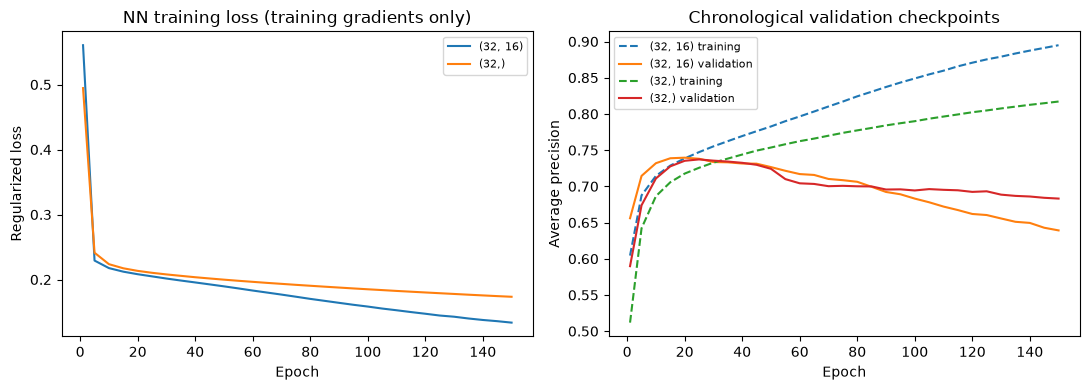

                 model      split  threshold  accuracy  precision   recall       F1  ROC_AUC   PR_AUC  average_precision
   Logistic regression      train       0.33  0.894249   0.597600 0.775701 0.675102 0.932443 0.689749           0.690305
   Logistic regression validation       0.33  0.904884   0.666667 0.735043 0.699187 0.931146 0.730846           0.733270
         Random forest      train       0.49  0.933961   0.808894 0.698858 0.749861 0.973038 0.866440           0.866513
         Random forest validation       0.49  0.916452   0.740741 0.683761 0.711111 0.930589 0.738035           0.739633
Shallow neural network      train       0.49  0.909251   0.685225 0.664590 0.674750 0.943086 0.738384           0.738629
Shallow neural network validation       0.49  0.913882   0.723214 0.692308 0.707424 0.925999 0.738263           0.739587


,model,parameters,validation_AP
0,Shallow neural network,"{""hidden_layer_sizes"": [32], ""alpha"": 0.01, ""s...",0.737203
1,Shallow neural network,"{""hidden_layer_sizes"": [32, 16], ""alpha"": 0.01...",0.739587


In [20]:
all_models, three_model_validation, nn_trials = train_shallow_network(model, numeric_features, categorical_features, statistical_models, OUT)
display(nn_trials)

## 12. Feature-group ablation and two preprocessing-order experiments

Retrain a fixed random forest after removing each of the six feature groups separately. Keep rows, RF settings and decision threshold fixed. Experiment 1 compares imputation/scaling orders; experiment 2 compares clipping/scaling orders after imputation. Both order variants use a fixed logistic-regression model and omit numeric missing indicators to isolate the comparison at equal dimension. Bounds/statistics are learned on training only.

In [21]:
def feature_group_ablation(model, numeric, categorical, registry, models, out):
    tr,va = [model.loc[model.split.eq(s)] for s in ['train','validation']]
    info = models['Random forest']
    records = []
    groups = sorted(registry.group.unique())
    for removed in ['none']+groups:
        omitted = set(registry.loc[registry.group.eq(removed),'feature'])
        nums = [c for c in numeric if c not in omitted]
        cats = [c for c in categorical if c not in omitted]
        pipe = Pipeline([('preprocess',make_preprocessor(nums,cats)),
                         ('model',clone(info['pipeline'].named_steps['model']))])
        pipe.fit(tr[nums+cats],tr.podium)
        p = pipe.predict_proba(va[nums+cats])[:,1]
        records.append({'removed_group':removed,'removed_features':'; '.join(sorted(omitted)),
            'validation_rows':len(va),'fixed_threshold':info['threshold'],**metrics(va.podium,p,info['threshold'])})
    results = pd.DataFrame(records)
    baseline = results.loc[results.removed_group.eq('none'),'average_precision'].iloc[0]
    results['AP_drop_from_full'] = baseline-results.average_precision
    results.to_csv(Path(out)/'feature_group_ablation.csv',index=False)
    fig,ax = plt.subplots(figsize=(9,4))
    shown = results.loc[results.removed_group.ne('none')].sort_values('AP_drop_from_full')
    ax.barh(shown.removed_group,shown.AP_drop_from_full,color=np.where(shown.AP_drop_from_full.ge(0),'#0f766e','#b45309'))
    ax.axvline(0,color='#64748b')
    ax.set(title='Remove one group and retrain the fixed random forest',xlabel='Validation AP drop (negative = ablation improved AP)')
    save_figure(fig,out,'10_feature_group_ablation')
    print(results[['removed_group','average_precision','F1','AP_drop_from_full']].to_string(index=False))
    return results


def preprocessing_order_experiments(model, numeric, categorical, models, out):
    tr,va = [model.loc[model.split.eq(s)] for s in ['train','validation']]
    features = numeric+categorical
    lr = clone(models['Logistic regression']['pipeline'].named_steps['model'])
    threshold = models['Logistic regression']['threshold']
    impute = lambda:SimpleImputer(strategy='median',keep_empty_features=True)
    orders = [
        ('1','impute_then_scale',[('impute',impute()),('scale',StandardScaler())]),
        ('1','scale_then_impute',[('scale',StandardScaler()),('impute',impute())]),
        ('2','impute_clip_scale',[('impute',impute()),('clip',QuantileClipper()),('scale',StandardScaler())]),
        ('2','impute_scale_clip',[('impute',impute()),('scale',StandardScaler()),('clip',QuantileClipper())])]
    results,distributions,transforms = [],[],{}
    for experiment,order,steps in orders:
        numeric_pipe = Pipeline(steps)
        prep = ColumnTransformer([('numeric',numeric_pipe,numeric),
            ('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical)],sparse_threshold=0)
        pipe = Pipeline([('preprocess',prep),('model',clone(lr))])
        pipe.fit(tr[features],tr.podium)
        p = pipe.predict_proba(va[features])[:,1]
        results.append({'experiment':experiment,'order':order,'fixed_threshold':threshold,
                        **metrics(va.podium,p,threshold)})
        z = pipe.named_steps['preprocess'].named_transformers_['numeric'].transform(tr[numeric])
        transforms[order] = z
        for i,c in enumerate(numeric):
            distributions.append({'experiment':experiment,'order':order,'feature':c,
                'mean':np.mean(z[:,i]),'std':np.std(z[:,i]),'min':np.min(z[:,i]),'max':np.max(z[:,i])})
    results,distributions = pd.DataFrame(results),pd.DataFrame(distributions)
    results.to_csv(Path(out)/'preprocessing_order_results.csv',index=False)
    distributions.to_csv(Path(out)/'preprocessing_distribution_effects.csv',index=False)
    for experiment in ['1','2']:
        subset = results.loc[results.experiment.eq(experiment)]
        fig,axes = plt.subplots(1,2,figsize=(12,4))
        axes[0].bar(subset.order,subset.average_precision,color=['#64748b','#0f766e'])
        axes[0].set(title='Experiment '+experiment+': validation AP',ylabel='Average precision',ylim=(0,1))
        feature = 'q1_gap_to_best'
        for order in subset.order:
            axes[1].hist(transforms[order][:,numeric.index(feature)],bins=35,alpha=.5,label=order,density=True)
        axes[1].set(title='Effect on training '+feature,xlabel='Transformed value',ylabel='Density')
        axes[1].legend(fontsize=8)
        axes[0].tick_params(axis='x',labelsize=8)
        save_figure(fig,out,'11_preprocessing_order_'+experiment)
    print(results.to_string(index=False))
    return results,distributions


def feature_detail_plots(model, numeric, categorical, out):
    """Readable report appendix panels supplement the dense batch-1 overview."""
    tr = model.loc[model.split.eq('train')]
    features = numeric+categorical
    names = []
    for start in range(0,len(features),4):
        fig,axes = plt.subplots(2,2,figsize=(9,7))
        for ax,c in zip(axes.ravel(),features[start:start+4]):
            if c in numeric and tr[c].nunique()>8:
                rates = tr.groupby(pd.qcut(tr[c],5,duplicates='drop'),observed=True).podium.agg(['mean','size'])
            else:
                rates = tr.groupby(c,observed=True).podium.agg(['mean','size']).sort_values('size',ascending=False).head(10)
            ax.bar(range(len(rates)),rates['mean'])
            ax.set_xticks(range(len(rates)),[str(i) for i in rates.index],rotation=45,ha='right',fontsize=8)
            ax.set(title=c,ylabel='Training podium rate',ylim=(0,1))
        for ax in axes.ravel()[len(features[start:start+4]):]: ax.axis('off')
        name = f'12_feature_detail_{start//4+1}'
        save_figure(fig,out,name)
        names.append(name)
    return names


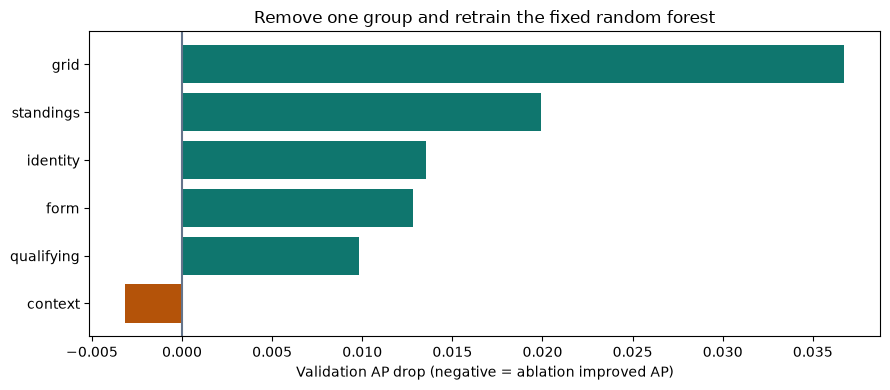

removed_group  average_precision       F1  AP_drop_from_full
         none           0.739633 0.711111           0.000000
      context           0.742775 0.696429          -0.003142
         form           0.726830 0.693694           0.012802
         grid           0.702900 0.702703           0.036732
     identity           0.726082 0.690583           0.013550
   qualifying           0.729836 0.675926           0.009796
    standings           0.719737 0.700000           0.019896


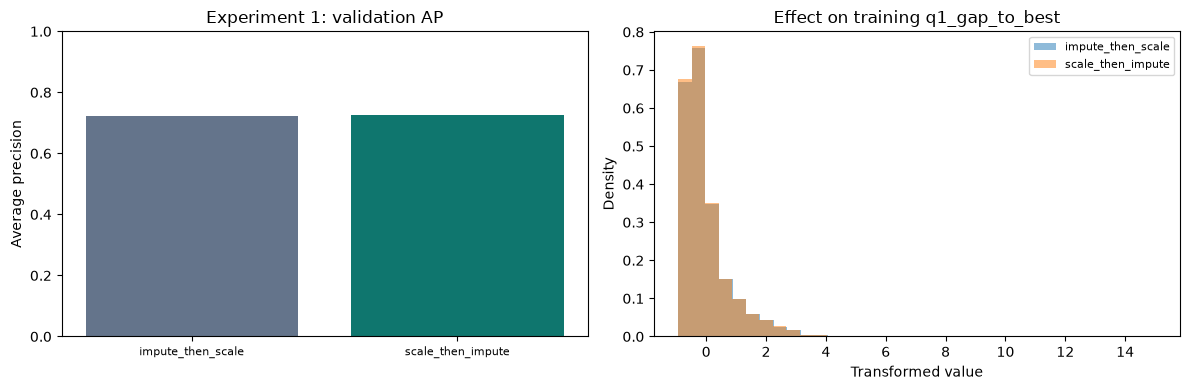

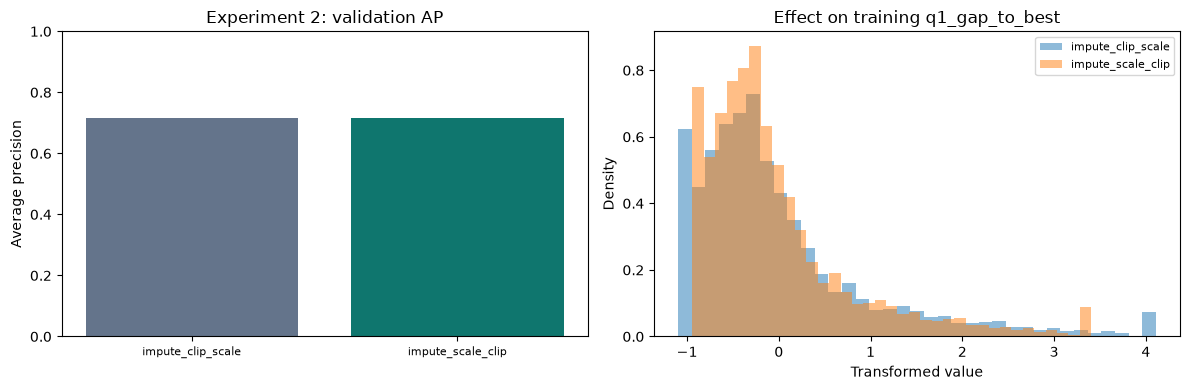

experiment             order  fixed_threshold  accuracy  precision   recall       F1  ROC_AUC   PR_AUC  average_precision
         1 impute_then_scale             0.33  0.901028   0.653846 0.726496 0.688259 0.926387 0.721576           0.724031
         1 scale_then_impute             0.33  0.901028   0.653846 0.726496 0.688259 0.926465 0.722285           0.724731
         2 impute_clip_scale             0.33  0.906170   0.671875 0.735043 0.702041 0.924952 0.711613           0.714862
         2 impute_scale_clip             0.33  0.906170   0.671875 0.735043 0.702041 0.924978 0.712283           0.715525


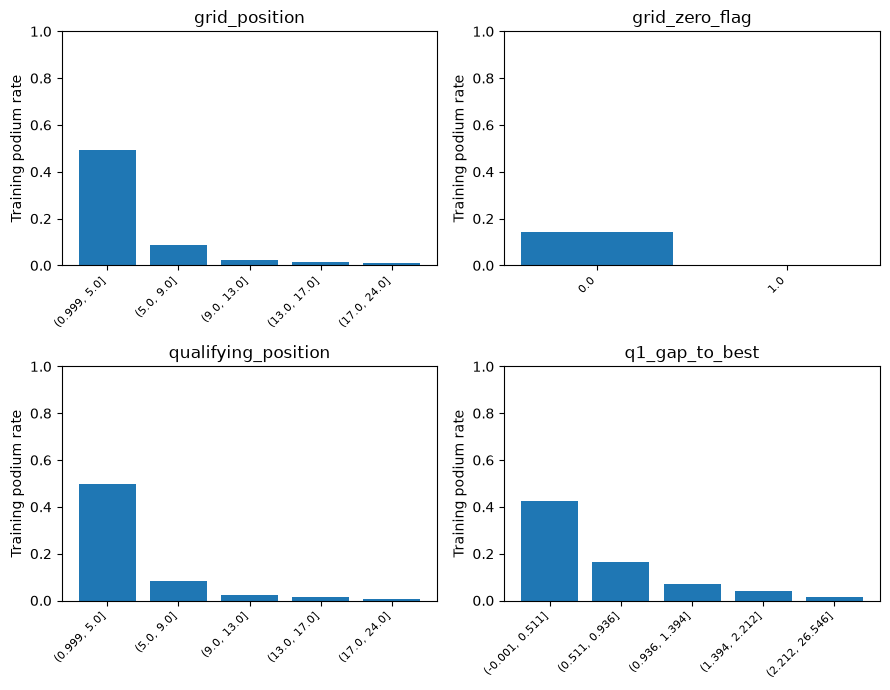

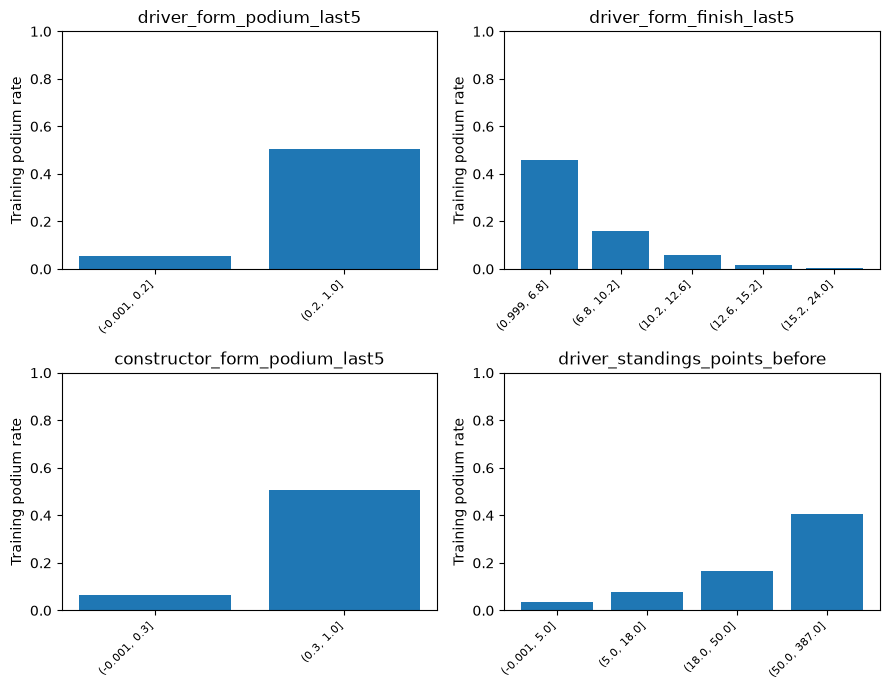

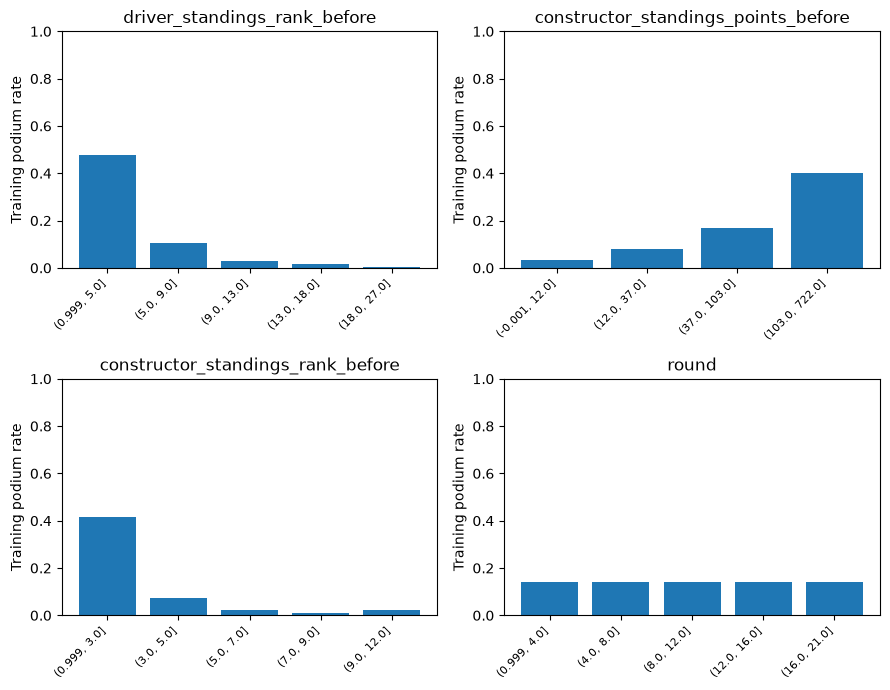

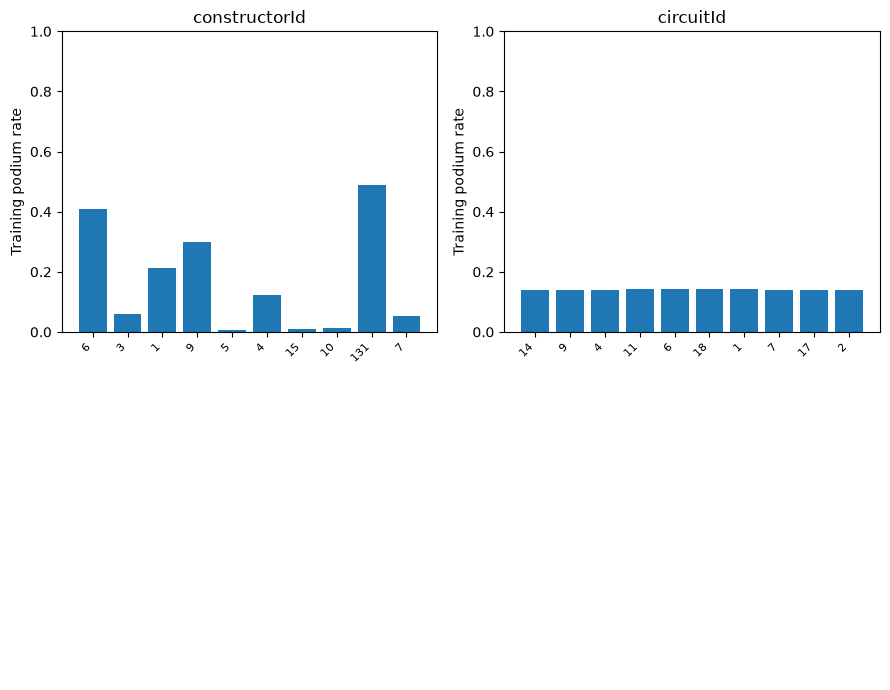

In [22]:
ablation_results = feature_group_ablation(model, numeric_features, categorical_features, feature_register, all_models, OUT)
order_results, distribution_effects = preprocessing_order_experiments(model, numeric_features, categorical_features, all_models, OUT)
feature_detail_names = feature_detail_plots(model, numeric_features, categorical_features, OUT)

## 13a. Inference on complete and partially missing pre-race records

The callable consumes engineered pre-race features, uses the fitted pipeline without refitting, handles missing fields, and rejects unknown/outcome columns. Demonstrate both records for every model and verify fitted-model hashes remain unchanged. Scores are not asserted to be calibrated probabilities.

In [23]:
def podium_inference(record, models, numeric, categorical, model_name):
    """Predict from engineered PRE-RACE features without learning from the input."""
    if model_name not in models:
        raise ValueError(f'Unknown model: {model_name}')
    features = numeric+categorical
    if not isinstance(record,dict) or not record:
        raise ValueError('Supply a non-empty dictionary of engineered pre-race features.')
    extra = set(record)-set(features)
    if extra:
        raise ValueError(f'Unknown/outcome fields are forbidden: {sorted(extra)}')
    row = pd.DataFrame([{c:record.get(c,np.nan) for c in features}])
    missing = [c for c in features if pd.isna(row.at[0,c])]
    for c in numeric:
        row[c] = pd.to_numeric(row[c],errors='raise').astype(float)
        if np.isinf(row[c]).any(): raise ValueError(f'Infinite value: {c}')
    for c in categorical:
        row[c] = row[c].map(lambda x:'__UNKNOWN__' if pd.isna(x) else str(x))
    info = models[model_name]
    p = float(info['pipeline'].predict_proba(row[features])[0,1])
    return {'model':model_name,'podium_probability':p,'threshold':float(info['threshold']),
        'predicted_podium':int(p>=info['threshold']),'missing_features':missing,
        'input_contract':'engineered pre-race features; caller must assemble history before cutoff',
        'probability_note':'Model score; probability calibration is not established.'}


def inference_demonstration(model, numeric, categorical, models, out):
    features = numeric+categorical
    va = model.loc[model.split.eq('validation')]
    complete = va.loc[va[features].notna().all(axis=1)].iloc[0]
    full_record = complete[features].to_dict()
    partial = full_record.copy()
    for c in ['q1_gap_to_best','qualifying_position','driver_standings_rank_before']:
        partial.pop(c)
    examples = []
    before = {n:joblib.hash(i['pipeline']) for n,i in models.items()}
    for name in models:
        for kind,record in [('complete',full_record),('partially_missing',partial)]:
            examples.append({'record_kind':kind,**podium_inference(record,models,numeric,categorical,name)})
    after = {n:joblib.hash(i['pipeline']) for n,i in models.items()}
    assert before==after, 'Inference must not modify fitted pipelines.'
    write_json(Path(out)/'inference_examples.json',{'raceId':int(complete.raceId),
        'driverId':int(complete.driverId),'complete_record':full_record,'partial_record':partial,'predictions':examples})
    # Outcome keys must never be silently accepted at inference time.
    for forbidden in ['positionOrder','podium','statusId','laps','points']:
        try:
            podium_inference({**full_record,forbidden:1},models,numeric,categorical,next(iter(models)))
        except ValueError:
            pass
        else:
            raise AssertionError(f'Inference accepted forbidden outcome field {forbidden}')
    summary = pd.DataFrame([{k:v for k,v in e.items() if k in ['record_kind','model','podium_probability','threshold','predicted_podium']} for e in examples])
    summary.to_csv(Path(out)/'inference_examples.csv',index=False)
    print(summary.to_string(index=False))
    return summary,full_record


In [24]:
inference_examples, complete_pre_race_record = inference_demonstration(model, numeric_features, categorical_features, all_models, OUT)
display(inference_examples)

      record_kind                  model  podium_probability  threshold  predicted_podium
         complete    Logistic regression            0.734771       0.33                 1
partially_missing    Logistic regression            0.116876       0.33                 0
         complete          Random forest            0.773423       0.49                 1
partially_missing          Random forest            0.482510       0.49                 0
         complete Shallow neural network            0.786165       0.49                 1
partially_missing Shallow neural network            0.590157       0.49                 1


,record_kind,model,podium_probability,threshold,predicted_podium
0,complete,Logistic regression,0.734771,0.33,1
1,partially_missing,Logistic regression,0.116876,0.33,0
2,complete,Random forest,0.773423,0.49,1
3,partially_missing,Random forest,0.482510,0.49,0
4,complete,Shallow neural network,0.786165,0.49,1
5,partially_missing,Shallow neural network,0.590157,0.49,1


## 13b. Global and local explanations of the validation-selected model

Choose the model by validation AP. Compute raw-feature permutation importance, global SHAP on 48 validation records with training-only background, and local SHAP plus LIME for one complete record. Check SHAP additivity to the predicted probability; record LIME local fidelity. Explain model reliance, never causal effects. Sample/background dependence and artificial perturbations are limitations.

In [25]:
def explain_validation_model(model, numeric, categorical, models, out, local_record):
    features = numeric+categorical
    tr,va = [model.loc[model.split.eq(s)] for s in ['train','validation']]
    chosen_name = max(models,key=lambda n:models[n]['validation_AP'])
    pipe = models[chosen_name]['pipeline']
    permutation = permutation_importance(pipe,va[features],va.podium,scoring='average_precision',
        n_repeats=5,random_state=SEED,n_jobs=1)
    importance = pd.DataFrame({'feature':features,'AP_drop_mean':permutation.importances_mean,
                              'AP_drop_std':permutation.importances_std}).sort_values('AP_drop_mean')
    importance.to_csv(Path(out)/'global_permutation_importance.csv',index=False)
    fig,ax = plt.subplots(figsize=(9,6))
    ax.barh(importance.feature,importance.AP_drop_mean,xerr=importance.AP_drop_std,color='#0f766e')
    ax.axvline(0,color='#64748b')
    ax.set(title=chosen_name+': validation permutation importance',xlabel='AP drop after shuffling; error bars = repeat SD')
    save_figure(fig,out,'13_global_permutation')
    prep = pipe.named_steps['preprocess']
    estimator = pipe.named_steps['model']
    ztr = prep.transform(tr[features])
    local = pd.DataFrame([local_record],columns=features)
    sample = pd.concat([local,va[features].sample(n=47,random_state=SEED)],ignore_index=True)
    zsample = prep.transform(sample)
    rng = np.random.default_rng(SEED)
    background = ztr[rng.choice(len(ztr),size=32,replace=False)]
    encoded_names = list(prep.get_feature_names_out())
    tree_additivity_error = None
    if chosen_name=='Random forest':
        explainer = shap.TreeExplainer(estimator,data=background,feature_perturbation='interventional',
                                      model_output='probability',feature_names=encoded_names)
        explanation = explainer(zsample,check_additivity=True)
        phi = explanation.values[:,:,1] if explanation.values.ndim==3 else explanation.values
        base = explanation.base_values[:,1] if np.asarray(explanation.base_values).ndim==2 else explanation.base_values
        method = 'TreeSHAP, interventional probability output; 32 training background rows'
        tree_reconstructed = np.asarray(base).reshape(-1)+phi.sum(axis=1)
        tree_additivity_error = float(np.max(abs(tree_reconstructed-estimator.predict_proba(zsample)[:,1])))
    if chosen_name!='Random forest' or tree_additivity_error>2e-5:
        # Some TreeSHAP/runtime combinations fail probability additivity despite matching
        # internal forest predictions. Explain the actual callable instead; never relax
        # the acceptance tolerance or silently present the inconsistent decomposition.
        explainer = shap.Explainer(lambda z:estimator.predict_proba(z)[:,1],
            shap.maskers.Independent(background),algorithm='permutation',seed=SEED,feature_names=encoded_names)
        with threadpool_limits(limits=2):
            explanation = explainer(zsample,max_evals=2*(2*zsample.shape[1]+1),silent=True)
        phi,base = explanation.values,np.asarray(explanation.base_values)
        method = 'Permutation SHAP, two permutation cycles per row; 32 training background rows'
        if tree_additivity_error is not None:
            method += '; fallback after TreeSHAP failed the external probability-additivity check'
    probability = pipe.predict_proba(sample[features])[:,1]
    reconstructed = np.asarray(base).reshape(-1)+phi.sum(axis=1)
    assert np.allclose(reconstructed,probability,atol=2e-5), 'SHAP output must reconstruct predicted probabilities.'
    pd.DataFrame({'probability':probability,'SHAP_baseline':np.asarray(base).reshape(-1),
        'SHAP_contribution_sum':phi.sum(axis=1),'reconstructed_probability':reconstructed,
        'absolute_error':abs(reconstructed-probability)}).to_csv(Path(out)/'shap_additivity_audit.csv',index=False)
    # Sum encoded/OHE and missing-indicator contributions back to original feature names.
    encoded_to_original = []
    for name in encoded_names:
        suffix = name.split('__',1)[1]
        if suffix.startswith('missingindicator_'):
            original = suffix.removeprefix('missingindicator_')
        elif name.startswith('category__'):
            original = next(c for c in categorical if suffix.startswith(c+'_'))
        else:
            original = suffix
        assert original in features,name
        encoded_to_original.append(original)
    grouped = np.column_stack([phi[:,np.array(encoded_to_original)==c].sum(axis=1) for c in features])
    assert np.allclose(grouped.sum(axis=1),phi.sum(axis=1))
    global_shap = pd.DataFrame({'feature':features,'mean_absolute_probability_contribution':np.abs(grouped).mean(axis=0)}).sort_values('mean_absolute_probability_contribution')
    global_shap.to_csv(Path(out)/'global_shap_importance.csv',index=False)
    pd.DataFrame(grouped,columns=features).to_csv(Path(out)/'sample_shap_contributions.csv',index=False)
    fig,ax = plt.subplots(figsize=(9,6))
    ax.barh(global_shap.feature,global_shap.mean_absolute_probability_contribution,color='#0f766e')
    ax.set(title=chosen_name+': global SHAP on 48 validation records',xlabel='Mean absolute contribution to podium probability')
    save_figure(fig,out,'14_global_shap')
    local_shap = shap.Explanation(values=grouped[0],base_values=float(np.asarray(base).reshape(-1)[0]),
        data=local.iloc[0].to_numpy(),feature_names=features)
    shap.plots.waterfall(local_shap,max_display=12,show=False)
    save_figure(plt.gcf(),out,'15_local_shap')
    pd.DataFrame({'feature':features,'contribution':grouped[0]}).to_csv(Path(out)/'local_shap_contributions.csv',index=False)
    # LIME uses the original feature grain with explicit categorical code/decode; it does not
    # independently toggle one-hot bits into impossible multi-team identities.
    medians = tr[numeric].median()
    lime_train = tr[features].copy()
    lime_local = local[features].copy()
    for c in numeric:
        lime_train[c] = lime_train[c].fillna(medians[c])
        lime_local[c] = lime_local[c].fillna(medians[c])
    category_names,category_maps = {},{}
    for c in categorical:
        levels = sorted(tr[c].unique().tolist())
        if local_record[c] not in levels: levels.append(local_record[c])
        mapping = {s:i for i,s in enumerate(levels)}
        category_maps[c] = levels
        category_names[features.index(c)] = levels
        lime_train[c] = lime_train[c].map(mapping)
        lime_local[c] = lime_local[c].map(mapping)
    category_names[features.index('grid_zero_flag')] = ['normal grid','zero grid']
    def lime_predict(z):
        frame = pd.DataFrame(z,columns=features)
        for c in categorical:
            levels = category_maps[c]
            frame[c] = [levels[int(np.clip(round(v),0,len(levels)-1))] for v in frame[c]]
        for c in ['grid_position','qualifying_position','round','grid_zero_flag']:
            frame[c] = frame[c].round()
        return pipe.predict_proba(frame[features])
    lime_explainer = LimeTabularExplainer(lime_train.to_numpy(dtype=float),feature_names=features,
        class_names=['Not podium','Podium'],categorical_features=sorted(category_names),
        categorical_names=category_names,random_state=SEED,discretize_continuous=True)
    local_lime = lime_explainer.explain_instance(lime_local.iloc[0].to_numpy(dtype=float),lime_predict,
        labels=(1,),num_features=10,num_samples=3000)
    lime_terms = pd.DataFrame(local_lime.as_list(label=1),columns=['condition','weight'])
    lime_terms.to_csv(Path(out)/'local_lime_weights.csv',index=False)
    save_figure(local_lime.as_pyplot_figure(label=1),out,'16_local_lime')
    info = {'explained_model':chosen_name,'SHAP_method':method,'validation_sample_rows':len(sample),
        'initial_TreeSHAP_max_additivity_error':tree_additivity_error,
        'background_source':'training rows only','SHAP_max_additivity_error':float(np.max(abs(reconstructed-probability))),
        'local_predicted_probability':float(probability[0]),'local_SHAP_baseline_probability':float(np.asarray(base).reshape(-1)[0]),
        'local_LIME_surrogate_R2':float(local_lime.score),'local_LIME_surrogate_probability':float(local_lime.local_pred[0]),
        'permutation_top_feature':str(importance.iloc[-1].feature),'SHAP_top_feature':str(global_shap.iloc[-1].feature),
        'limitation':'Explanations describe model reliance, not causal effects. Correlated features and artificial perturbations can distort attribution. SHAP is sample/background dependent; LIME is a local approximation, not an additive probability decomposition.'}
    write_json(Path(out)/'xai_summary.json',info)
    print(json.dumps(info,indent=2))
    return info,importance,global_shap,lime_terms


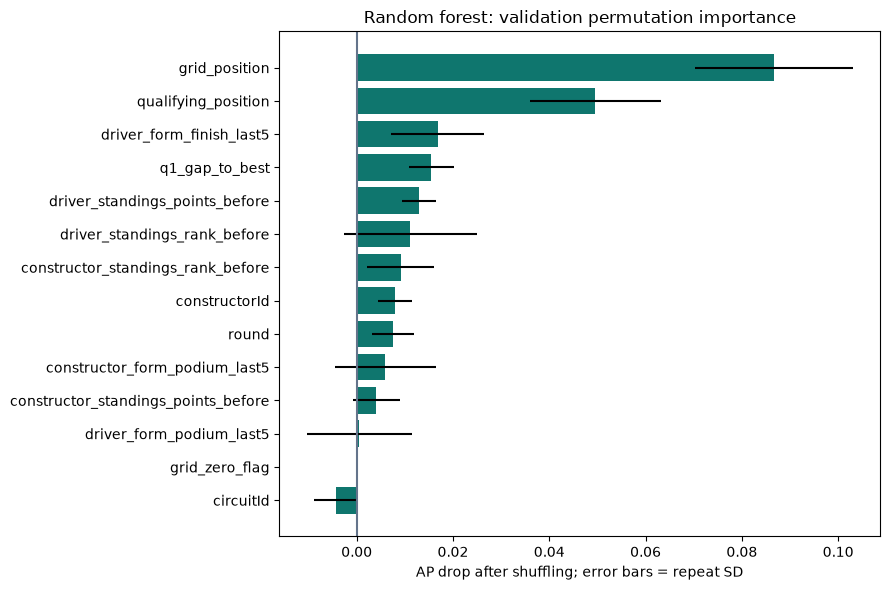

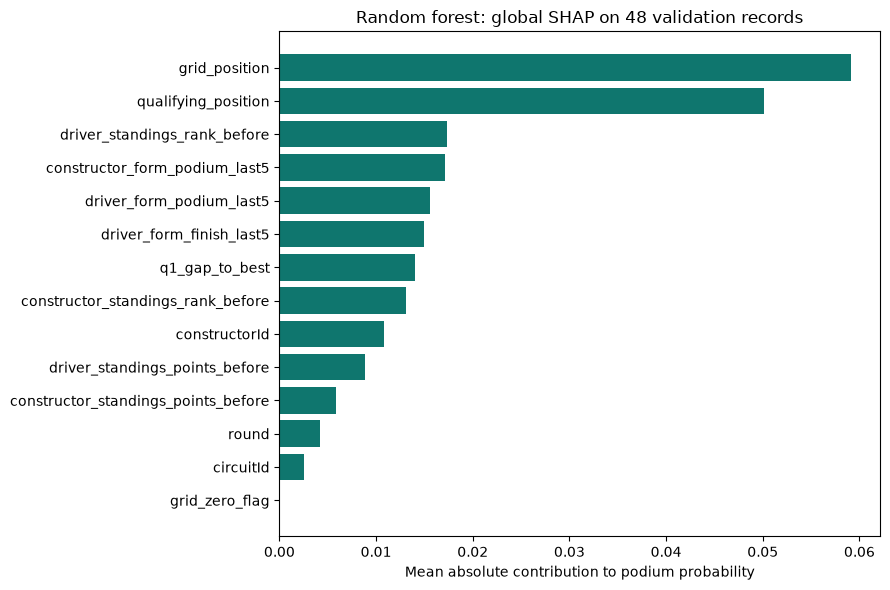

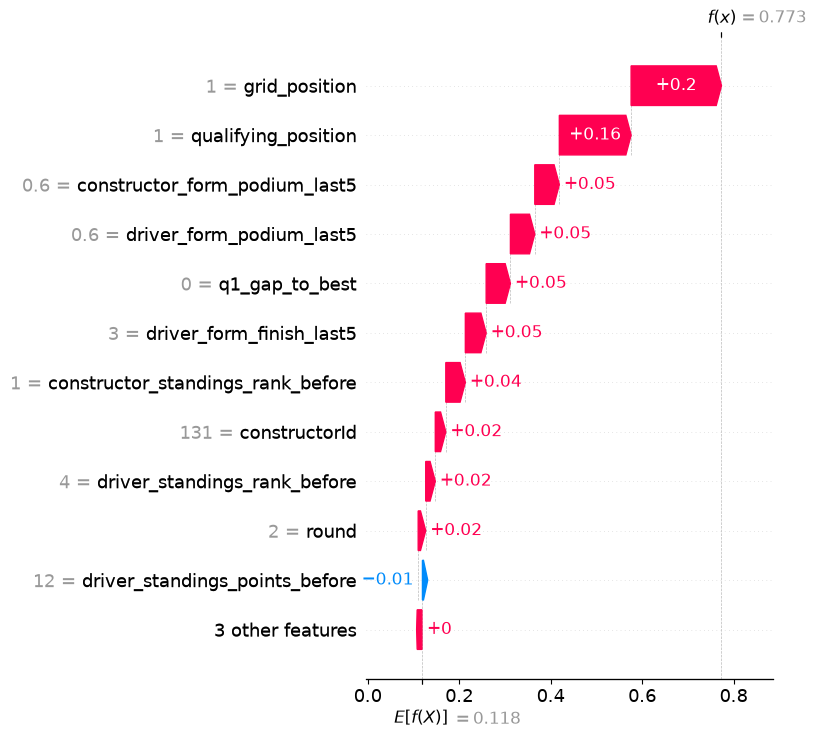

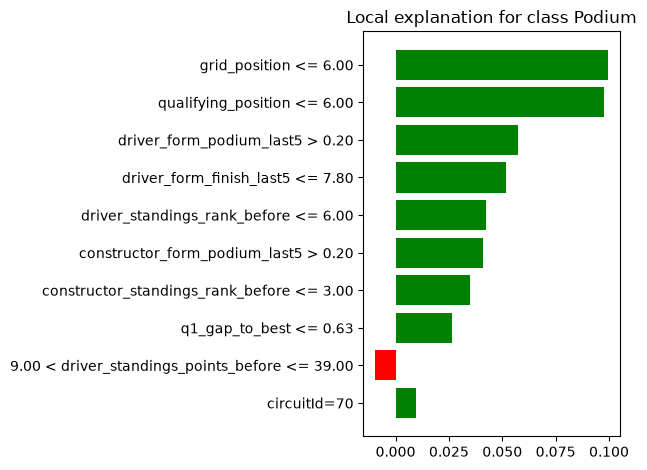

{
  "explained_model": "Random forest",
  "SHAP_method": "Permutation SHAP, two permutation cycles per row; 32 training background rows; fallback after TreeSHAP failed the external probability-additivity check",
  "validation_sample_rows": 48,
  "initial_TreeSHAP_max_additivity_error": 0.003532331643025244,
  "background_source": "training rows only",
  "SHAP_max_additivity_error": 7.771561172376096e-16,
  "local_predicted_probability": 0.7734225070079116,
  "local_SHAP_baseline_probability": 0.1183807601118739,
  "local_LIME_surrogate_R2": 0.680571943700498,
  "local_LIME_surrogate_probability": 0.4793199485571794,
  "permutation_top_feature": "grid_position",
  "SHAP_top_feature": "grid_position",
  "limitation": "Explanations describe model reliance, not causal effects. Correlated features and artificial perturbations can distort attribution. SHAP is sample/background dependent; LIME is a local approximation, not an additive probability decomposition."
}


,condition,weight
0,grid_position <= 6.00,0.099681
1,qualifying_position <= 6.00,0.097554
2,driver_form_podium_last5 > 0.20,0.057344
3,driver_form_finish_last5 <= 7.80,0.051698
4,driver_standings_rank_before <= 6.00,0.042472
5,constructor_form_podium_last5 > 0.20,0.041001
6,constructor_standings_rank_before <= 3.00,0.034732
7,q1_gap_to_best <= 0.63,0.026484
8,9.00 < driver_standings_points_before <= 39.00,-0.009602
9,circuitId=70,0.009358


In [26]:
xai_summary, permutation_table, shap_table, lime_table = explain_validation_model(model, numeric_features, categorical_features, all_models, OUT, complete_pre_race_record)
display(lime_table)

## 17–20. Freeze choices, then evaluate the three locked models

After all validation-driven work above, keep the full predeclared feature set and baseline main-model preprocessing. Freeze pipeline hashes, hyperparameters, NN checkpoint and thresholds before computing any test predictions. Report all six plan metrics plus separately defined AP on train/validation/test. A changed choice after test scoring raises an error rather than silently retuning.

In [27]:
def freeze_model_choices(model, numeric, categorical, models, out):
    """Called after all validation-driven experiments, before any test predictions."""
    features = numeric+categorical
    contents = {'features':features,'primary_selection_metric':'validation average precision',
        'chosen_model_for_inference':max(models,key=lambda n:models[n]['validation_AP']),
        'models':{n:{'parameters':i['parameters'],'threshold':i['threshold'],
                    'fitted_pipeline_hash':joblib.hash(i['pipeline'])} for n,i in models.items()},
        'row_hashes':{s:hashlib.sha256(model.loc[model.split.eq(s),KEY].to_csv(index=False).encode()).hexdigest()
                      for s in ['train','validation','test_reserved']},
        'decision':'Keep the complete predeclared feature set and baseline preprocessing for the main three-model comparison. Ablation/order experiments are diagnostic; no test-driven adoption.',
        'versions':{'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},'seed':SEED}
    digest = hashlib.sha256(json.dumps(contents,sort_keys=True,default=str).encode()).hexdigest()
    lock = Path(out)/'model_choices_frozen.json'
    if lock.exists() and (Path(out)/'three_model_metrics.csv').exists():
        old = json.loads(lock.read_text(encoding='utf-8'))
        if old['choice_sha256']!=digest:
            raise RuntimeError('Model choices changed after test evaluation. Stop and document the change; do not silently retune against the revealed test set.')
    contents['choice_sha256'] = digest
    contents['frozen_before_test_predictions'] = True
    write_json(lock,contents)
    print('Frozen model choices:',digest)
    return contents


def evaluate_frozen_models(model, numeric, categorical, models, frozen, out):
    features = numeric+categorical
    records,predictions = [],[]
    for name,info in models.items():
        assert joblib.hash(info['pipeline'])==frozen['models'][name]['fitted_pipeline_hash']
        for split in ['train','validation','test_reserved']:
            frame = model.loc[model.split.eq(split)]
            p = info['pipeline'].predict_proba(frame[features])[:,1]
            records.append({'model':name,'split':'test' if split=='test_reserved' else split,
                'threshold':info['threshold'],**metrics(frame.podium,p,info['threshold'])})
            if split=='test_reserved':
                predictions.append(frame[KEY+['podium']].assign(model=name,probability=p,threshold=info['threshold']))
    result = pd.DataFrame(records)
    result.to_csv(Path(out)/'three_model_metrics.csv',index=False)
    pd.concat(predictions,ignore_index=True).to_csv(Path(out)/'frozen_test_predictions.csv',index=False)
    test = model.loc[model.split.eq('test_reserved')]
    fig,axes = plt.subplots(1,2,figsize=(11,4.5))
    for name,info in models.items():
        p = info['pipeline'].predict_proba(test[features])[:,1]
        RocCurveDisplay.from_predictions(test.podium,p,name=name,ax=axes[0])
        PrecisionRecallDisplay.from_predictions(test.podium,p,name=name,ax=axes[1])
        fig_cm,ax_cm = plt.subplots(figsize=(4,3.5))
        ConfusionMatrixDisplay.from_predictions(test.podium,p>=info['threshold'],ax=ax_cm,
            display_labels=['Not podium','Podium'],colorbar=False)
        ax_cm.set_title(name+' — locked test')
        save_figure(fig_cm,out,'18_test_'+name.lower().replace(' ','_')+'_confusion')
    axes[0].set_title('Test ROC (choices frozen before scoring)')
    axes[1].axhline(test.podium.mean(),color='#64748b',linestyle='--',label='Test class prevalence')
    axes[1].legend(fontsize=7)
    axes[1].set_title('Test precision–recall (no retuning)')
    save_figure(fig,out,'17_frozen_test_curves')
    print(result.to_string(index=False))
    return result


def acceptance_checks_batch2(model, numeric, categorical, models, out):
    features = numeric+categorical
    assert len(models)==3
    assert not model.duplicated(KEY).any()
    assert set(model.podium.unique())=={0,1}
    contracts = [tuple(i['pipeline'].named_steps['preprocess'].get_feature_names_out()) for i in models.values()]
    assert all(c==contracts[0] for c in contracts)
    group_results = pd.read_csv(Path(out)/'feature_group_ablation.csv')
    assert len(group_results)==7
    order_results = pd.read_csv(Path(out)/'preprocessing_order_results.csv')
    assert order_results.groupby('experiment').size().eq(2).all()
    scored = pd.read_csv(Path(out)/'three_model_metrics.csv')
    assert len(scored)==9 and set(scored.split)=={'train','validation','test'}
    names = ['accuracy','precision','recall','F1','ROC_AUC','PR_AUC','average_precision']
    assert np.isfinite(scored[names].to_numpy()).all()
    assert scored[names].ge(0).all().all() and scored[names].le(1).all().all()
    assert not set(features)&{'podium','positionOrder','points','laps','statusId','milliseconds','rank'}
    results = {'same_rows_features_three_models':True,'unique_driver_race_keys':True,
        'six_feature_groups_ablated':True,'two_order_experiments_two_variants_each':True,
        'three_models_all_six_metrics_all_three_splits':True,'model_choices_locked_before_test':True,
        'global_SHAP_permutation_local_SHAP_LIME':True,'complete_and_missing_inference':True,
        'Kaggle_execution_verified':False,'all_team_members_reviewed':False,'official_submission_completed':False,
        'historical_cohort_ground_truth_fully_resolved':False,
        'notes':'Implemented checks pass. Kaggle synchronization remains blocked by the prior upload denial; team access/review and historical source ambiguities require verification. No perfect-score guarantee.'}
    write_json(Path(out)/'batch2_acceptance.json',results)
    print(json.dumps(results,indent=2))
    return results


Frozen model choices: f650c67a131721a39f46243d89dc94b2950b3d970971eb7f2a4ce79c8f4a37d3


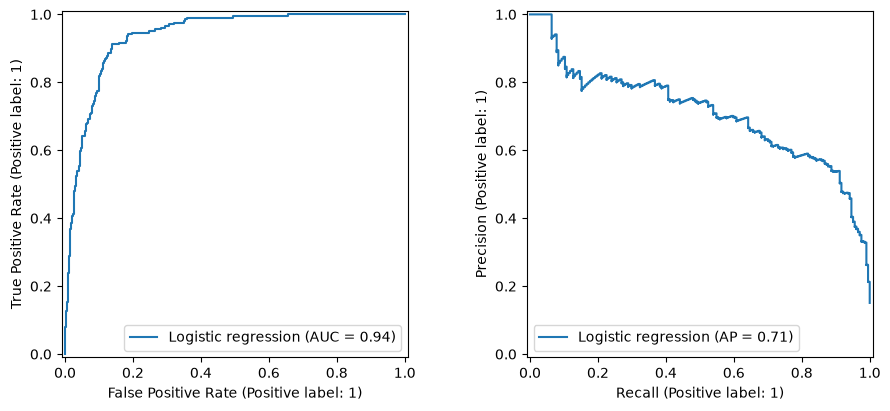

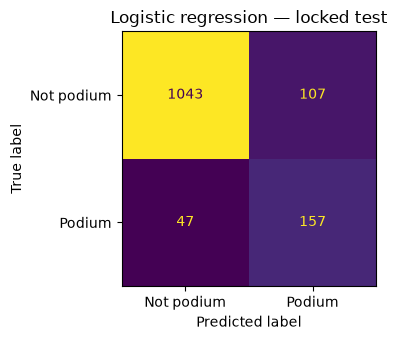

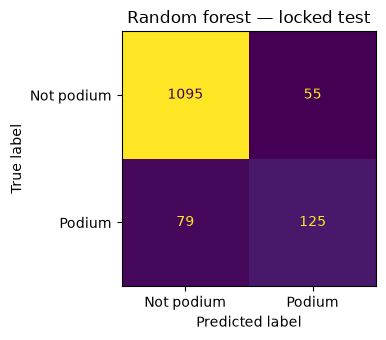

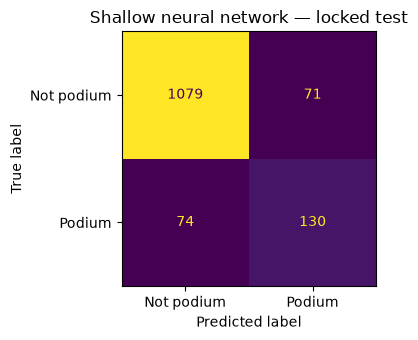

                 model      split  threshold  accuracy  precision   recall       F1  ROC_AUC   PR_AUC  average_precision
   Logistic regression      train       0.33  0.894249   0.597600 0.775701 0.675102 0.932443 0.689749           0.690305
   Logistic regression validation       0.33  0.904884   0.666667 0.735043 0.699187 0.931146 0.730846           0.733270
   Logistic regression       test       0.33  0.886263   0.594697 0.769608 0.670940 0.936790 0.708415           0.709524
         Random forest      train       0.49  0.933961   0.808894 0.698858 0.749861 0.973038 0.866440           0.866513
         Random forest validation       0.49  0.916452   0.740741 0.683761 0.711111 0.930589 0.738035           0.739633
         Random forest       test       0.49  0.901034   0.694444 0.612745 0.651042 0.939616 0.716390           0.717535
Shallow neural network      train       0.49  0.909251   0.685225 0.664590 0.674750 0.943086 0.738384           0.738629
Shallow neural network validatio

PASS: all 14 raw CSV hashes unchanged.


In [28]:
frozen_choices = freeze_model_choices(model, numeric_features, categorical_features, all_models, OUT)
final_model_metrics = evaluate_frozen_models(model, numeric_features, categorical_features, all_models, frozen_choices, OUT)
batch2_acceptance = acceptance_checks_batch2(model, numeric_features, categorical_features, all_models, OUT)
verify_raw_unchanged(DATA_DIR, raw_hashes)

## 14–16. Integrated analytical report and review handoff

The report incorporates both batches and all figures. Row 16 remains pending team review, successful Kaggle execution, and actual submission confirmation. The local PDF is generated from this same report after notebook execution.

In [29]:
"""Integrated report content derived from the complete run's measured evidence."""
from pathlib import Path
import json
import re
import pandas as pd

def write_integrated_report(out, destination):
    out, destination = Path(out), Path(destination)
    def read(name): return pd.read_csv(out/name)
    def get(name): return json.loads((out/name).read_text(encoding='utf-8'))
    def table(frame):
        def cell(v):
            if pd.isna(v): return '-'
            if isinstance(v,float): return f'{v:.4f}'
            return str(v).replace('|','/')
        return '\n'.join(['| '+' | '.join(map(str,frame.columns))+' |',
            '| '+' | '.join(['---']*len(frame.columns))+' |']+
            ['| '+' | '.join(cell(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None)])
    def fig(name,caption): return f'![{caption}](figures/{name}.png)\n\n{caption}'
    first = (out/'batch1_report.md').read_text(encoding='utf-8')
    first = first.split('## Statistical-model comparison')[0]
    first = first.replace('# ACL Milestone 1 — batch 1 report draft (work packages 1–10)',
        '# ACL Milestone 1 - Formula 1 Podium Prediction')
    first = re.sub(r'\*\*Status:\*\*[^\n]+',
        '**Status:** integrated implementation of work packages 1-20; team review, Kaggle verification and official submission remain pending.',first,count=1)
    first = first.replace('Batch 2 ablation will assess group contribution.','The ablation section below measures group contribution.')
    first = first.replace('test is reserved at 2022–2024','test is held out at 2022–2024 until the choice-freeze step')
    first = first.replace('../outputs/batch1/figures/','figures/')
    score = read('three_model_metrics.csv')
    short = {'Logistic regression':'LR','Random forest':'RF','Shallow neural network':'NN'}
    shown = score.copy()
    shown['model'] = shown.model.map(short)
    compact = shown[['model','split','accuracy','precision','recall','F1','ROC_AUC','PR_AUC','average_precision']].rename(columns={'average_precision':'AP'})
    frozen = get('model_choices_frozen.json')
    xai = get('xai_summary.json')
    ablation = read('feature_group_ablation.csv')
    orders = read('preprocessing_order_results.csv')
    order_index = orders.set_index('order')
    infer = read('inference_examples.csv')
    infer['model'] = infer.model.map(short)
    trials = read('nn_model_trials.csv')
    nn_params = frozen['models']['Shallow neural network']['parameters']
    test = score.loc[score.split.eq('test')]
    validation = score.loc[score.split.eq('validation')]
    selected = frozen['chosen_model_for_inference']
    selected_test = test.set_index('model').loc[selected]
    full_ap = ablation.loc[ablation.removed_group.eq('none'),'average_precision'].iloc[0]
    strongest = ablation.loc[ablation.removed_group.ne('none')].sort_values('AP_drop_from_full',ascending=False).iloc[0]
    worse = ablation.loc[ablation.removed_group.ne('none') & ablation.AP_drop_from_full.lt(0)]
    q1 = read('q1_front_row_rates.csv')
    q1leaders = q1.groupby('era').head(3)
    supported = q1.loc[q1.starts.ge(10)].groupby('era').head(3)
    contributions = read('local_shap_contributions.csv')
    positive = contributions.sort_values('contribution',ascending=False).head(3)
    negative = contributions.sort_values('contribution').head(3)
    def terms(frame): return ', '.join(f'{r.feature} ({r.contribution:+.4f})' for r in frame.itertuples())
    sections = [
        '## Team and contribution verification',
        'Team listed in the shared plan: Amr Hazem Mohamed Mohamed Hassan Elkotit; Mark Bassem Mourad Samoel Emira; Loay Mohamed Sabry Farag Ismail; Karim Ahmed Mahmoud Abdelmageed. Existing work-package ownership remains unchanged. Implementation assistance does not prove individual contributions or understanding; each member must review and defend the complete notebook. Contribution sign-off is pending.',
        '## Additional detail for Question 1 - unfiltered versus supported leaders',
        'The full ranking answers the question for every observed circuit; the supported display excludes fewer than 10 front-row starts to avoid presenting a tiny denominator as a stable best circuit. The unfiltered leaders below may be based on very few starts:',
        table(q1leaders[['era','circuit_name','starts','podiums','rate']]),
        'Supported leaders (at least 10 starts) are:',table(supported[['era','circuit_name','starts','podiums','rate']]),
        'The Indianapolis 500 event is excluded, not every race at Indianapolis Motor Speedway: the later United States Grand Prix on its road course remains eligible.',
        '## Three-model training, selection and comparison',
        'Logistic regression (LR) is the statistical baseline: regularized linear log-odds, transparent but limited for nonlinear interactions. The random forest (RF) averages 250 trees; it represents interactions but can overfit and is sensitive to distribution shifts. The shallow feed-forward neural network (NN) uses ReLU hidden units and an Adam optimizer with L2 regularization alpha = 0.01. It can represent nonlinearities but is sensitive to scaling, optimization choices, random initialization, and overfitting.',
        'LR candidates use C = 0.1, 1, 10; RF candidates use max_depth = 6 or 12 with min_samples_leaf = 3. NN trials use hidden layers (32,) and (32, 16), each trained for up to 150 epochs. Gradients use 2003-2019 only. Checkpoints at epoch 1 and every 5 epochs are selected by explicit 2020-2021 validation AP, with the earliest checkpoint retained on ties. No internal random validation split is used. Validation F1 selects thresholds from 0.05 to 0.95; the default 0.5 is not assumed optimal.',
        f'Selected NN configuration: hidden layers {nn_params["hidden_layer_sizes"]}, checkpoint epoch {nn_params["selected_epoch"]}. The complete training and validation histories are preserved in nn_training_history.csv. The two architectural trials are:',
        table(trials[['parameters','validation_AP']]),
        fig('09_nn_training','Training loss and chronological validation AP show whether additional training improves generalization rather than only fit to training data.'),
        'All three models use the same driver-race rows, the same 14 canonical input features, and matching encoded feature names. Each main pipeline fits median imputation with missing indicators, numeric scaling and one-hot categorical encoding on training only. Unknown categories map to all-zero one-hot values and remain a documented limitation. Class balancing/resampling is not introduced; the task is assessed with minority-class-aware precision-recall metrics.',
        'Metric definitions: accuracy is the fraction of correct binary decisions; precision is the fraction of predicted podiums that are podiums; recall is the fraction of actual podiums found; F1 is their harmonic mean at the locked threshold. ROC-AUC assesses ranking across false/true-positive tradeoffs. PR-AUC is trapezoidal area under precision versus recall. Average precision (AP) is a separate step-weighted precision-recall summary. AP drives validation selection; PR-AUC, F1 and ROC-AUC supply complementary evidence. Accuracy alone can conceal the podium minority. The brief lists three named metrics but also refers to five; all six plan metrics plus AP are provided, and the wording remains for course verification.',
        '### Decisions fixed before test evaluation',
        f'The selected inference model is {selected}, chosen using validation AP only. All models keep the full predeclared feature set and baseline preprocessing. Ablation and order experiments below are diagnostic, not a basis for test-driven changes. Fitted-pipeline hashes, row hashes, hyperparameters, NN checkpoint and thresholds were recorded before any test predictions. Choice manifest SHA-256: {frozen["choice_sha256"]}.',
        'The 2022-2024 results below were computed only after that freeze. They cannot be used to select a different winner, threshold, feature set or preprocessing order. Re-running an identical frozen pipeline checks reproducibility; it does not make the already revealed test set new evidence for further tuning.',
        table(pd.DataFrame([{'model':short[name],'threshold':values['threshold'],'settings':json.dumps(values['parameters'])} for name,values in frozen['models'].items()])),
        '### Training, validation and held-out test metrics',
        'LR = logistic regression; RF = random forest; NN = shallow neural network. Every metric is computed on the same split rows for all models. Training figures are descriptive and optimistically biased; validation was used for selection. Test figures are the locked-model generalization check.',
        table(compact),
        f'The validation-selected {selected} has test F1 {selected_test.F1:.4f}, ROC-AUC {selected_test.ROC_AUC:.4f}, PR-AUC {selected_test.PR_AUC:.4f}, and AP {selected_test.average_precision:.4f}. This reports performance without claiming perfect accuracy or choosing a new model after observing test results.',
        'RF and NN validation AP are nearly tied (0.739633 versus 0.739587); this small observed difference does not establish a statistically reliable superiority. RF has substantially higher training AP than validation AP, consistent with overfitting. On the held-out test, LR has higher F1/recall at its locked threshold while RF has higher AP/ROC-AUC; the choice of ranking metric versus thresholded decisions therefore changes the apparent ordering. These are descriptive comparisons, not permission to select a new winner using test results.',
        fig('08_statistical_model_curves','Statistical-model validation ROC and precision-recall curves from the initial batch.'),
        fig('logistic_regression_confusion','LR validation decisions at its validation-selected threshold.'),
        fig('random_forest_confusion','RF validation decisions at its validation-selected threshold.'),
        fig('17_frozen_test_curves','Locked three-model test ROC and precision-recall curves. The test prevalence line contextualizes PR performance.'),
    ]
    for name in frozen['models']:
        sections.append(fig('18_test_'+name.lower().replace(' ','_')+'_confusion',name+' test confusion matrix at the locked validation-selected threshold.'))
    sections += [
        '## Controlled experiments',
        '### Feature-group ablation',
        'The probe model is RF with its validation-selected settings and threshold fixed. Retrain once after dropping each of grid, qualifying, form, standings, context, and identity, using identical training/validation rows. Missing-indicator and one-hot columns are regenerated from each reduced training feature set. This measures group reliance in this model under correlation, not a causal contribution or the value of an isolated individual feature.',
        table(ablation[['removed_group','average_precision','F1','AP_drop_from_full']]),
        f'Full-model validation AP is {full_ap:.4f}. The largest AP reduction follows removing {strongest.removed_group} ({strongest.AP_drop_from_full:.4f}). '+
        ('Groups whose removal improved AP: '+', '.join(worse.removed_group)+'. Negative drops are retained rather than hidden.' if len(worse) else 'No group removal improved validation AP in this run.'),
        'Correlated feature groups can substitute for one another. A small ablation drop does not establish irrelevance; apparent improvement may reflect variance or overfitting. The main comparison keeps the full feature set fixed for this milestone rather than making additional validation-guided revisions after revealing test scores.',
        fig('10_feature_group_ablation','AP decrease from dropping each group; negative values mean the reduced model improved validation AP.'),
        '### Preprocessing-order experiment 1',
        'Compare median-impute then standardize against standardize observed values (NaNs ignored during fitting) then median-impute. Both use the same numeric/categorical inputs, fixed LR C and threshold, identical rows, and no numeric missing-indicator expansion for equal experimental dimension. The main three-model pipelines retain their indicators; these experimental scores are not silently substituted into that main comparison.',
        table(orders.loc[orders.experiment.astype(str).eq('1'),['order','average_precision','F1','ROC_AUC','PR_AUC']]),
        f'Observed validation AP changes from {order_index.loc["impute_then_scale","average_precision"]:.6f} to {order_index.loc["scale_then_impute","average_precision"]:.6f} when scaling first. F1 is unchanged at {order_index.loc["scale_then_impute","F1"]:.6f}: the small ranking change does not alter the locked-threshold decisions in this run. This is not evidence of a reliable improvement across future seasons.',
        'Imputing before scaling changes the fitted variance because imputed observations participate in scale statistics. Scaling first estimates moments from observed values; later median imputation does not retroactively change those moments. If a feature has no missing values, the two orders may be equivalent for that feature.',
        fig('11_preprocessing_order_1','Experiment 1 validation AP and training distribution of transformed Q1 gap.'),
        '### Preprocessing-order experiment 2',
        'After training-only median imputation, compare training 1st/99th-percentile clipping then scaling against scaling then clipping with bounds learned in the transformed training space. Same rows, LR settings, categories and threshold are held fixed. Clipping changes extremes; fitting scale before versus after clipping changes centering and variance. No quantile bounds are learned from validation/test.',
        table(orders.loc[orders.experiment.astype(str).eq('2'),['order','average_precision','F1','ROC_AUC','PR_AUC']]),
        f'Observed validation AP changes from {order_index.loc["impute_clip_scale","average_precision"]:.6f} to {order_index.loc["impute_scale_clip","average_precision"]:.6f} when scaling before clipping. Both orders have F1 {order_index.loc["impute_scale_clip","F1"]:.6f}. The range audit shows the clipping orders substantially reduce extreme transformed Q1 gaps relative to the unclipped experiment, while their modest AP difference does not justify a new post-test model choice.',
        fig('11_preprocessing_order_2','Experiment 2 validation AP and transformed training Q1-gap distributions; detailed range/moment effects are saved per feature.'),
        '### Effects on distributions, ranges and values',
        'The numeric transformation audit records each training feature’s transformed mean, standard deviation, minimum and maximum for every order. The following example illustrates the effect; the complete table is delivered alongside the report.',
        table(read('preprocessing_distribution_effects.csv').loc[lambda d:d.feature.eq('q1_gap_to_best')]),
        '## Model explainability',
        f'The explained model is the validation-selected {xai["explained_model"]}. Permutation importance shuffles each canonical input over validation data and measures AP drop, with five seeded repeats. Correlated inputs may share importance; shuffling can produce implausible combinations. The top permutation feature in this run is {xai["permutation_top_feature"]}.',
        fig('13_global_permutation','Global model reliance measured as validation AP loss after feature shuffling; bars may be negative and error bars show repeat SD, not confidence intervals.'),
        f'Global SHAP method: {xai["SHAP_method"]}. Forty-eight validation records are explained using a training-only background. Encoded/OHE and missing-indicator contributions are summed back to original input features; mean absolute contributions summarize that sample. The leading feature is {xai["SHAP_top_feature"]}. Background/sample choices and dependent features affect these attributions.',
        ('The initial TreeSHAP decomposition failed the external probability-additivity check (maximum error '+f'{xai["initial_TreeSHAP_max_additivity_error"]:.6f}'+'). The reported explanations therefore use permutation SHAP of the actual fitted prediction callable; the tolerance was not relaxed. This affects the explanation method, not the fitted classifier or its predictions.' if xai.get('initial_TreeSHAP_max_additivity_error',0) and xai['initial_TreeSHAP_max_additivity_error']>2e-5 else 'SHAP reconstruction was checked directly against the fitted pipeline probabilities.'),
        fig('14_global_shap','Global SHAP: mean absolute probability contribution on the stated validation sample, not a population-wide causal effect.'),
        f'For one complete validation record, predicted podium probability is {xai["local_predicted_probability"]:.4f}, compared with SHAP baseline {xai["local_SHAP_baseline_probability"]:.4f}. Largest positive contributions: {terms(positive)}. Most negative contributions: {terms(negative)}. Maximum additivity error across the explained records is {xai["SHAP_max_additivity_error"]:.3g}.',
        fig('15_local_shap','Local SHAP probability decomposition for the stated record; contributions plus baseline reconstruct the model probability.'),
        f'A local LIME explanation is also supplied to cover the final checklist’s LIME wording. It uses training data, explicit categorical decoding, and 3,000 perturbed neighbors. Surrogate local R-squared is {xai["local_LIME_surrogate_R2"]:.4f}; surrogate probability is {xai["local_LIME_surrogate_probability"]:.4f}. R-squared describes the surrogate’s neighborhood fit, not the classifier’s prediction accuracy. A low value limits confidence in the local approximation. Correlated/engineered variables can still form unrealistic perturbed combinations.',
        f'The surrogate differs from the classifier probability at this record by {abs(xai["local_LIME_surrogate_probability"]-xai["local_predicted_probability"]):.4f}. That material approximation error limits the strength of the local LIME interpretation; its weights must not be treated as an exact probability decomposition.',
        table(read('local_lime_weights.csv')),
        fig('16_local_lime','LIME weights describe a local surrogate; they are neither causal effects nor an exact SHAP-style probability decomposition.'),
        'All explanations describe how the model relies on the supplied data representation. They do not establish that changing a feature causes a podium. SHAP and LIME may differ because they use different neighborhoods, backgrounds and approximation objectives.',
        '## Inference function and missing-data handling',
        'podium_inference accepts a non-empty dictionary of the 14 engineered pre-race features. The caller must construct historical form/standings using only information before the cutoff. Missing numeric fields use the fitted training imputer; missing/unseen categorical identities use the encoder’s unknown-category behavior. Unknown or post-race keys are rejected. The function calls predict_proba without fitting, returns the locked threshold and binary prediction, and reports missing fields. Model hashes are asserted unchanged before/after the demonstrations.',
        'Complete and partially missing examples are evaluated for every model on the same validation record; the partial example omits Q1 gap, qualifying position and prior driver rank. Results are:',
        table(infer),
        'The probability is an uncalibrated model score, not a guaranteed real-world frequency. Each driver is classified independently, so predictions need not sum to exactly three podiums in a race; the brief requests binary classification rather than constrained race rankings.',
        '## Limitations and review items',
        'Historical cohort reconstruction remains uncertain for shared drives, some pit-lane starts and zero-lap start failures. The deterministic rule and withheld cases are documented; independent event-by-event ground-truth verification is not claimed. A modern 2003+ modeling window reduces some historical ambiguity but changes the modeled population. Recorded final grids are interpreted as pre-start positions; the CSVs are not timestamped snapshots of last-minute decisions.',
        'Question 2 controls starting position through broad grid strata; within-bin, driver, team, circuit and era confounding remain. Dual-nationality mapping exclusions and Indianapolis exclusions affect the comparison. Question 3 uses a conservative status taxonomy; vague retirement/damage/tyre/wing causes can undercount mechanical failures. Constructor renames reset identity history rather than being silently merged.',
        'Repeated validation selection can overfit the validation window; no uncertainty intervals or probability calibration are claimed. Validation/test include different sporting/technical eras. Explanations depend on representation, background, sample and perturbation assumptions. Feature evidence and ablations demonstrate association/model reliance, not causation.',
        'The brief’s metric-count wording and local-LIME checklist wording remain explicit verification items. Providing all six plan metrics plus AP and both local SHAP/LIME covers the named outputs but does not invent an official clarification.',
        '## Reproducibility and acceptance state',
        'Source hashes, semantic conversions, PK/FK integrity, unique driver-race keys, chronological source-event lineage, race-disjoint splits, feature whitelists, three-model row/feature contracts, inference immutability and SHAP additivity are checked in code. The notebook executes from a fresh local kernel. Independent perturbation checks verify that current/future outcomes or standings cannot change current/earlier features.',
        'Private GitHub review: [PR #2](https://github.com/amrelkotit/Acl_9th_project/pull/2). Shared Kaggle: [Acl_9th_project](https://www.kaggle.com/code/amrelkotit/acl-9th-project). The existing Kaggle draft was preserved as backup version 5. Upload permission was denied earlier; the updated notebook has not been synchronized or verified in Kaggle. All four members’ access, full review, and oral evaluation preparation remain unverified.',
        'Row 16 is not complete: this PDF is prepared for review, but the official submission form has not been submitted and no confirmation is claimed. Submission deadline in the course brief is 18 October 2026 at 11:59 PM; evaluation dates/slot reservation are separately announced. Do not treat a local successful run as completed team review or official submission.',
        '## Appendix - detailed feature evidence',
        'These larger panels supplement the compact overview and make the training-only feature evidence readable. Category plots show the ten most frequent categories; they do not establish incremental predictive benefit.',
    ]
    for number in range(1,5):
        sections.append(fig(f'12_feature_detail_{number}',f'Training feature-evidence panel {number}; candidate rationale and missingness are documented in feature_register.csv.'))
    sections += [
        '## Sources and methods references',
        '- MS1 Description (Project).pdf, pp. 1-8: official supplied milestone requirements.',
        '- Introduction for Formula 1 Beginners (Project).pdf, pp. 1-7: domain interpretation and historical cautions.',
        '- [Assignment-cited Kaggle/Ergast dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020), downloaded snapshot hashes in source_manifest.json.',
        '- [scikit-learn leakage and preprocessing guidance](https://scikit-learn.org/stable/common_pitfalls.html).',
        '- [scikit-learn MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).',
        '- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html) and [SHAP PermutationExplainer](https://shap.readthedocs.io/en/latest/generated/shap.PermutationExplainer.html).',
        '- [LIME tabular explanation documentation](https://lime-ml.readthedocs.io/en/latest/lime.html).',
    ]
    text = first+'\n\n'+'\n\n'.join(sections)+'\n'
    destination.parent.mkdir(parents=True,exist_ok=True)
    destination.write_text(text,encoding='utf-8')
    # Every saved analysis plot must occur in the integrated report, not only selected successes.
    referenced = {Path(p).name for p in re.findall(r'!\[[^]]*\]\(([^)]*)\)',text)}
    actual = {p.name for p in (out/'figures').glob('*.png')}
    assert actual==referenced, f'Figure coverage mismatch: missing={actual-referenced}, unknown={referenced-actual}'
    return text


integrated_report = write_integrated_report(OUT, OUT/"milestone1_report.md")
display(Markdown(re.sub(r"!\[[^]]*\]\([^)]*\)", "[Figure displayed in the matching notebook section]", integrated_report)))

# ACL Milestone 1 - Formula 1 Podium Prediction



**Status:** integrated implementation of work packages 1-20; team review, Kaggle verification and official submission remain pending.



## Objective and scope

Predict whether an eligible race starter finishes on the podium using information available after qualifying and before the main race. The binary label is positionOrder ≤ 3; exact finishing-position prediction is outside scope. Descriptive questions use historical outcomes, but those current-race outcomes never enter the predictor whitelist.



## Source and audit

Source: [the assignment-cited Kaggle/Ergast dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020). The downloaded snapshot contains all 14 tables and results for all 24 races in 2024. Source_manifest.json records per-file SHA-256 and runtime versions. Every run checks that raw hashes are unchanged.



| table | rows | columns | primary_key | null_PK_rows | duplicate_PK_rows | missing_cells |
| --- | --- | --- | --- | --- | --- | --- |
| circuits | 77 | 9 | circuitId | 0 | 0 | 0 |
| constructors | 212 | 5 | constructorId | 0 | 0 | 0 |
| constructor_results | 12625 | 5 | constructorResultsId | 0 | 0 | 12608 |
| constructor_standings | 13391 | 7 | constructorStandingsId | 0 | 0 | 0 |
| drivers | 861 | 9 | driverId | 0 | 0 | 1559 |
| driver_standings | 34863 | 7 | driverStandingsId | 0 | 0 | 0 |
| races | 1125 | 18 | raceId | 0 | 0 | 11349 |
| results | 26759 | 18 | resultId | 0 | 0 | 122887 |
| qualifying | 10494 | 9 | qualifyId | 0 | 0 | 11668 |
| lap_times | 589081 | 6 | raceId, driverId, lap | 0 | 0 | 0 |
| pit_stops | 11371 | 7 | raceId, driverId, stop | 0 | 0 | 0 |
| sprint_results | 360 | 16 | resultId | 0 | 0 | 73 |
| seasons | 75 | 2 | year | 0 | 0 | 0 |
| status | 139 | 2 | statusId | 0 | 0 | 0 |



Implemented candidate-key checks found no null/duplicate primary keys; the documented foreign-key checks found no orphan values. Per-column schemas and missingness are in column_inventory.csv and each tested relationship is in foreign_key_checks.csv. These checks establish properties of this snapshot, not externally enforced database constraints.



## Cleaning, cohort and duplicate rule

Cleaning replaces literal backslash-N and blank tokens with actual missing values on working copies. Numeric columns, dates, and qualifying/lap/pit-stop durations receive semantic types; duration values are also represented in seconds. Conversion failures are counted and must be zero. Missing Q2/Q3 can be structural non-advancement; the baseline does not impute these as if every driver participated.



Raw results: 26,759 rows. Non-qualifier exclusions: 1,365; documented non-start exclusions: 257; uncertain zero-grid/zero-lap entries withheld: 38. Duplicate rows removed after eligibility filtering: 88. Final historical cohort: 25,011 unique driver–race rows.



Within duplicate driver–race groups, prefer a positive-grid source row over a zero-grid handover and break ties using the smallest resultId. Finishing position and target are never used to select the feature row. The target belongs to that retained source row; historical shared-drive outcomes may differ under another justified rule. All affected source rows and selections are retained in duplicate_resolution.csv. Historical starting-car identity is not always recoverable; do not interpret the rule as verified ground truth for every shared drive.



A zero grid is kept when there is evidence of race participation (positive laps), including pit-lane starters; zero-grid/zero-lap uncertain entries are separately withheld. Zero is not ranked ahead of pole. Status and laps are used only for retrospective cohort auditing/labels, never predictors. Results alone cannot independently establish every DNS or pit-lane start, especially positive-grid zero-lap engine/accident cases. This is conditional prediction for reconstructed starters, not a model of which entrants will start.



[Figure displayed in the matching notebook section]

Before/after cleaning and cohort construction; unchanged missing-cell totals reflect representation changes, not unexplained imputation.



[Figure displayed in the matching notebook section]

Qualifying coverage by season; the training portion supports beginning the modeling window in 2003.



[Figure displayed in the matching notebook section]

Changing field sizes and podium prevalence make historical and modern eras non-exchangeable.



## Question 1 — front-row starts by circuit and the 2014 boundary

Join path: results → races → circuits, with qualifying joined on (raceId, driverId) to distinguish qualifying rank from starting grid. Grain: one retained eligible driver–race. Numerator: podium finishes among actual grid 1/2 starts; denominator: those front-row starts. Compare 1950–2013 against 2014–2024. Indianapolis 500 is excluded as an explicitly different competition format. Grid missing/zero cases are outside front-row denominators; missing qualifying rows do not remove known-grid starts.



The highest supported rates (at least 10 front-row starts for this display; the unfiltered table is also saved) are:



| era | circuit_name | starts | podiums | rate |
| --- | --- | --- | --- | --- |
| 1950–2013 | Circuit de Nevers Magny-Cours | 36 | 29 | 0.8056 |
| 1950–2013 | Istanbul Park | 14 | 11 | 0.7857 |
| 1950–2013 | Indianapolis Motor Speedway | 14 | 11 | 0.7857 |
| 2014–2024 | Suzuka Circuit | 18 | 16 | 0.8889 |
| 2014–2024 | Yas Marina Circuit | 22 | 19 | 0.8636 |
| 2014–2024 | Circuit de Monaco | 20 | 17 | 0.8500 |



Among circuits observed in both periods, 24 have different within-era ranks. Rankings also depend on changing circuit participation and small denominators; they are descriptive, not controlled causal comparisons. The full q1_circuit_changes.csv records common-circuit rate changes.



[Figure displayed in the matching notebook section]

Front-row-to-podium conversion, with numerator/denominator labels; qualifying position is not substituted for grid.



## Question 2 — home-race podiums controlling starting grid

Join path: results → races → circuits, and results → drivers. Map nationality to country explicitly (British → UK; Monegasque → Monaco; USA/United States normalized). Ambiguous dual-nationality entries are withheld rather than guessed. Indianapolis is excluded. Only mapped starters with positive grid positions enter this comparison.



Control method: stratify grid into 1–2, 3–5, 6–10, 11–15, and 16+, then apply the same pooled grid-stratum weights to home and away rates on common support. The notebook saves each stratum’s counts and weights. This does not eliminate within-bin differences or driver/team/era confounding.



| group | raw_podium_rate | grid_standardized_rate |
| --- | --- | --- |
| Away | 0.1379 | 0.1366 |
| Home | 0.1166 | 0.1321 |



Grid-standardized home-minus-away difference: -0.45 percentage points. Rows excluded for unmapped nationality: 3; mapped rows lacking positive grid: 72. This association does not establish a causal home advantage.



[Figure displayed in the matching notebook section]

Within-grid-stratum rates and standardized home/away rates.



## Question 3 — constructor mechanical retirements

Join path: results → status, results → races, and results → constructors. Periods are 2014–2021 and 2022–2024. Numerator: verified component/system failure statuses in the documented conservative mapping. Denominator: eligible constructor driver-starts, not race weekends or all entrants. Lapped finishers are finished, not retired. Accidents, driver causes, and regulatory decisions are excluded from mechanical failures.



| constructorId | constructor_name | period | starts | mechanical_retirements | ambiguous_statuses | mechanical_rate |
| --- | --- | --- | --- | --- | --- | --- |
| 207 | Caterham | 2014–2021 | 34 | 8 | 3 | 0.2353 |
| 208 | Lotus F1 | 2014–2021 | 75 | 13 | 5 | 0.1733 |
| 5 | Toro Rosso | 2014–2021 | 242 | 39 | 5 | 0.1612 |
| 4 | Renault | 2014–2021 | 200 | 27 | 6 | 0.1350 |
| 1 | McLaren | 2014–2021 | 319 | 43 | 8 | 0.1348 |
| 51 | Alfa Romeo | 2022–2024 | 88 | 10 | 1 | 0.1136 |
| 214 | Alpine F1 Team | 2022–2024 | 136 | 15 | 0 | 0.1103 |
| 213 | AlphaTauri | 2022–2024 | 88 | 6 | 1 | 0.0682 |
| 3 | Williams | 2022–2024 | 134 | 7 | 4 | 0.0522 |
| 6 | Ferrari | 2022–2024 | 135 | 7 | 3 | 0.0519 |



Each constructorId is analyzed separately; renames are not silently combined. Generic Retired, damage, tyre/puncture, wing and other ambiguous causes are not assumed mechanical: their counts are saved in q3_ambiguous_status_counts.csv. Reported mechanical rates may therefore undercount failures with vague cause labels. Denominator size and constructor lifetimes differ.



[Figure displayed in the matching notebook section]

Mechanical retirements per constructor driver-start, with count labels.



## Features and chronological evaluation design

Model window: 2003–2024, chosen because training-only coverage is consistently near-complete from 2003, while 1996–2002 coverage is patchy. Training is 2003–2019; validation is 2020–2021; test is held out at 2022–2024 until the choice-freeze step. Earlier rows are retained for historical questions and prior-race history. All rows from one race stay in the same split.



Driver form shifts each history before rolling over up to five earlier starts. Constructor form first aggregates each race then shifts before rolling, so the teammate’s current result cannot leak. Standings use the most recent strictly earlier main race within the same season, with source-event assertions and season-start handling. Earlier validation/test races may supply observed history for later races, corresponding to sequential pre-race deployment. Current-weekend sprint results are deliberately excluded; no claim is made that every sprint format shares the same cutoff.



| feature | group | source | training_missing_fraction | training_spearman_with_podium |
| --- | --- | --- | --- | --- |
| grid_position | grid | results.grid | 0.0028 | -0.4944 |
| grid_zero_flag | grid | results.grid | 0.0000 | -0.0215 |
| qualifying_position | qualifying | qualifying.position | 0.0031 | -0.4967 |
| q1_gap_to_best | qualifying | qualifying.q1 | 0.0181 | -0.3972 |
| driver_form_podium_last5 | form | earlier results | 0.0110 | 0.5268 |
| driver_form_finish_last5 | form | earlier results | 0.0110 | -0.4432 |
| constructor_form_podium_last5 | form | earlier results | 0.0051 | 0.5148 |
| driver_standings_points_before | standings | driver_standings + races | 0.0000 | 0.3706 |
| driver_standings_rank_before | standings | driver_standings + races | 0.0713 | -0.4778 |
| constructor_standings_points_before | standings | constructor_standings + races | 0.0000 | 0.3624 |
| constructor_standings_rank_before | standings | constructor_standings + races | 0.0568 | -0.4465 |
| round | context | races.round | 0.0000 | -0.0001 |
| constructorId | identity | results.constructorId | 0.0000 | — |
| circuitId | context | races.circuitId | 0.0000 | — |



Feature hypotheses: grid/qualifying represent starting opportunity and qualifying pace; driver and constructor form represent recent competitiveness; prior standings represent season strength; constructor and circuit identities represent team/circuit context; round represents championship progress. The training-only plots show associations and missingness; these motivate candidate inclusion but do not establish incremental predictive value. The ablation section below measures group contribution. IDs are one-hot categorical values, not continuous ranks. Model selection and preprocessing never fit on validation/test rows.



[Figure displayed in the matching notebook section]

Training-only evidence for the candidate features; associations are not causal effects.





## Team and contribution verification

Team listed in the shared plan: Amr Hazem Mohamed Mohamed Hassan Elkotit; Mark Bassem Mourad Samoel Emira; Loay Mohamed Sabry Farag Ismail; Karim Ahmed Mahmoud Abdelmageed. Existing work-package ownership remains unchanged. Implementation assistance does not prove individual contributions or understanding; each member must review and defend the complete notebook. Contribution sign-off is pending.

## Additional detail for Question 1 - unfiltered versus supported leaders

The full ranking answers the question for every observed circuit; the supported display excludes fewer than 10 front-row starts to avoid presenting a tiny denominator as a stable best circuit. The unfiltered leaders below may be based on very few starts:

| era | circuit_name | starts | podiums | rate |
| --- | --- | --- | --- | --- |
| 1950–2013 | Circuit of the Americas | 4 | 4 | 1.0000 |
| 1950–2013 | Donington Park | 2 | 2 | 1.0000 |
| 1950–2013 | Ain Diab | 2 | 2 | 1.0000 |
| 2014–2024 | Miami International Autodrome | 6 | 6 | 1.0000 |
| 2014–2024 | Autódromo Internacional do Algarve | 4 | 4 | 1.0000 |
| 2014–2024 | Las Vegas Strip Street Circuit | 4 | 4 | 1.0000 |

Supported leaders (at least 10 starts) are:

| era | circuit_name | starts | podiums | rate |
| --- | --- | --- | --- | --- |
| 1950–2013 | Circuit de Nevers Magny-Cours | 36 | 29 | 0.8056 |
| 1950–2013 | Istanbul Park | 14 | 11 | 0.7857 |
| 1950–2013 | Indianapolis Motor Speedway | 14 | 11 | 0.7857 |
| 2014–2024 | Suzuka Circuit | 18 | 16 | 0.8889 |
| 2014–2024 | Yas Marina Circuit | 22 | 19 | 0.8636 |
| 2014–2024 | Circuit de Monaco | 20 | 17 | 0.8500 |

The Indianapolis 500 event is excluded, not every race at Indianapolis Motor Speedway: the later United States Grand Prix on its road course remains eligible.

## Three-model training, selection and comparison

Logistic regression (LR) is the statistical baseline: regularized linear log-odds, transparent but limited for nonlinear interactions. The random forest (RF) averages 250 trees; it represents interactions but can overfit and is sensitive to distribution shifts. The shallow feed-forward neural network (NN) uses ReLU hidden units and an Adam optimizer with L2 regularization alpha = 0.01. It can represent nonlinearities but is sensitive to scaling, optimization choices, random initialization, and overfitting.

LR candidates use C = 0.1, 1, 10; RF candidates use max_depth = 6 or 12 with min_samples_leaf = 3. NN trials use hidden layers (32,) and (32, 16), each trained for up to 150 epochs. Gradients use 2003-2019 only. Checkpoints at epoch 1 and every 5 epochs are selected by explicit 2020-2021 validation AP, with the earliest checkpoint retained on ties. No internal random validation split is used. Validation F1 selects thresholds from 0.05 to 0.95; the default 0.5 is not assumed optimal.

Selected NN configuration: hidden layers [32, 16], checkpoint epoch 20. The complete training and validation histories are preserved in nn_training_history.csv. The two architectural trials are:

| parameters | validation_AP |
| --- | --- |
| {"hidden_layer_sizes": [32], "alpha": 0.01, "solver": "adam", "learning_rate_init": 0.001, "selected_epoch": 25, "max_checked_epoch": 150, "checkpoint_selection": "highest validation AP; earliest checkpoint on ties"} | 0.7372 |
| {"hidden_layer_sizes": [32, 16], "alpha": 0.01, "solver": "adam", "learning_rate_init": 0.001, "selected_epoch": 20, "max_checked_epoch": 150, "checkpoint_selection": "highest validation AP; earliest checkpoint on ties"} | 0.7396 |

[Figure displayed in the matching notebook section]

Training loss and chronological validation AP show whether additional training improves generalization rather than only fit to training data.

All three models use the same driver-race rows, the same 14 canonical input features, and matching encoded feature names. Each main pipeline fits median imputation with missing indicators, numeric scaling and one-hot categorical encoding on training only. Unknown categories map to all-zero one-hot values and remain a documented limitation. Class balancing/resampling is not introduced; the task is assessed with minority-class-aware precision-recall metrics.

Metric definitions: accuracy is the fraction of correct binary decisions; precision is the fraction of predicted podiums that are podiums; recall is the fraction of actual podiums found; F1 is their harmonic mean at the locked threshold. ROC-AUC assesses ranking across false/true-positive tradeoffs. PR-AUC is trapezoidal area under precision versus recall. Average precision (AP) is a separate step-weighted precision-recall summary. AP drives validation selection; PR-AUC, F1 and ROC-AUC supply complementary evidence. Accuracy alone can conceal the podium minority. The brief lists three named metrics but also refers to five; all six plan metrics plus AP are provided, and the wording remains for course verification.

### Decisions fixed before test evaluation

The selected inference model is Random forest, chosen using validation AP only. All models keep the full predeclared feature set and baseline preprocessing. Ablation and order experiments below are diagnostic, not a basis for test-driven changes. Fitted-pipeline hashes, row hashes, hyperparameters, NN checkpoint and thresholds were recorded before any test predictions. Choice manifest SHA-256: f650c67a131721a39f46243d89dc94b2950b3d970971eb7f2a4ce79c8f4a37d3.

The 2022-2024 results below were computed only after that freeze. They cannot be used to select a different winner, threshold, feature set or preprocessing order. Re-running an identical frozen pipeline checks reproducibility; it does not make the already revealed test set new evidence for further tuning.

| model | threshold | settings |
| --- | --- | --- |
| LR | 0.3300 | {"C": 1.0} |
| RF | 0.4900 | {"max_depth": 12, "min_samples_leaf": 3, "n_estimators": 250} |
| NN | 0.4900 | {"hidden_layer_sizes": [32, 16], "alpha": 0.01, "solver": "adam", "learning_rate_init": 0.001, "selected_epoch": 20, "max_checked_epoch": 150, "checkpoint_selection": "highest validation AP; earliest checkpoint on ties"} |

### Training, validation and held-out test metrics

LR = logistic regression; RF = random forest; NN = shallow neural network. Every metric is computed on the same split rows for all models. Training figures are descriptive and optimistically biased; validation was used for selection. Test figures are the locked-model generalization check.

| model | split | accuracy | precision | recall | F1 | ROC_AUC | PR_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| LR | train | 0.8942 | 0.5976 | 0.7757 | 0.6751 | 0.9324 | 0.6897 | 0.6903 |
| LR | validation | 0.9049 | 0.6667 | 0.7350 | 0.6992 | 0.9311 | 0.7308 | 0.7333 |
| LR | test | 0.8863 | 0.5947 | 0.7696 | 0.6709 | 0.9368 | 0.7084 | 0.7095 |
| RF | train | 0.9340 | 0.8089 | 0.6989 | 0.7499 | 0.9730 | 0.8664 | 0.8665 |
| RF | validation | 0.9165 | 0.7407 | 0.6838 | 0.7111 | 0.9306 | 0.7380 | 0.7396 |
| RF | test | 0.9010 | 0.6944 | 0.6127 | 0.6510 | 0.9396 | 0.7164 | 0.7175 |
| NN | train | 0.9093 | 0.6852 | 0.6646 | 0.6747 | 0.9431 | 0.7384 | 0.7386 |
| NN | validation | 0.9139 | 0.7232 | 0.6923 | 0.7074 | 0.9260 | 0.7383 | 0.7396 |
| NN | test | 0.8929 | 0.6468 | 0.6373 | 0.6420 | 0.9314 | 0.6841 | 0.6853 |

The validation-selected Random forest has test F1 0.6510, ROC-AUC 0.9396, PR-AUC 0.7164, and AP 0.7175. This reports performance without claiming perfect accuracy or choosing a new model after observing test results.

RF and NN validation AP are nearly tied (0.739633 versus 0.739587); this small observed difference does not establish a statistically reliable superiority. RF has substantially higher training AP than validation AP, consistent with overfitting. On the held-out test, LR has higher F1/recall at its locked threshold while RF has higher AP/ROC-AUC; the choice of ranking metric versus thresholded decisions therefore changes the apparent ordering. These are descriptive comparisons, not permission to select a new winner using test results.

[Figure displayed in the matching notebook section]

Statistical-model validation ROC and precision-recall curves from the initial batch.

[Figure displayed in the matching notebook section]

LR validation decisions at its validation-selected threshold.

[Figure displayed in the matching notebook section]

RF validation decisions at its validation-selected threshold.

[Figure displayed in the matching notebook section]

Locked three-model test ROC and precision-recall curves. The test prevalence line contextualizes PR performance.

[Figure displayed in the matching notebook section]

Logistic regression test confusion matrix at the locked validation-selected threshold.

[Figure displayed in the matching notebook section]

Random forest test confusion matrix at the locked validation-selected threshold.

[Figure displayed in the matching notebook section]

Shallow neural network test confusion matrix at the locked validation-selected threshold.

## Controlled experiments

### Feature-group ablation

The probe model is RF with its validation-selected settings and threshold fixed. Retrain once after dropping each of grid, qualifying, form, standings, context, and identity, using identical training/validation rows. Missing-indicator and one-hot columns are regenerated from each reduced training feature set. This measures group reliance in this model under correlation, not a causal contribution or the value of an isolated individual feature.

| removed_group | average_precision | F1 | AP_drop_from_full |
| --- | --- | --- | --- |
| none | 0.7396 | 0.7111 | 0.0000 |
| context | 0.7428 | 0.6964 | -0.0031 |
| form | 0.7268 | 0.6937 | 0.0128 |
| grid | 0.7029 | 0.7027 | 0.0367 |
| identity | 0.7261 | 0.6906 | 0.0136 |
| qualifying | 0.7298 | 0.6759 | 0.0098 |
| standings | 0.7197 | 0.7000 | 0.0199 |

Full-model validation AP is 0.7396. The largest AP reduction follows removing grid (0.0367). Groups whose removal improved AP: context. Negative drops are retained rather than hidden.

Correlated feature groups can substitute for one another. A small ablation drop does not establish irrelevance; apparent improvement may reflect variance or overfitting. The main comparison keeps the full feature set fixed for this milestone rather than making additional validation-guided revisions after revealing test scores.

[Figure displayed in the matching notebook section]

AP decrease from dropping each group; negative values mean the reduced model improved validation AP.

### Preprocessing-order experiment 1

Compare median-impute then standardize against standardize observed values (NaNs ignored during fitting) then median-impute. Both use the same numeric/categorical inputs, fixed LR C and threshold, identical rows, and no numeric missing-indicator expansion for equal experimental dimension. The main three-model pipelines retain their indicators; these experimental scores are not silently substituted into that main comparison.

| order | average_precision | F1 | ROC_AUC | PR_AUC |
| --- | --- | --- | --- | --- |
| impute_then_scale | 0.7240 | 0.6883 | 0.9264 | 0.7216 |
| scale_then_impute | 0.7247 | 0.6883 | 0.9265 | 0.7223 |

Observed validation AP changes from 0.724031 to 0.724731 when scaling first. F1 is unchanged at 0.688259: the small ranking change does not alter the locked-threshold decisions in this run. This is not evidence of a reliable improvement across future seasons.

Imputing before scaling changes the fitted variance because imputed observations participate in scale statistics. Scaling first estimates moments from observed values; later median imputation does not retroactively change those moments. If a feature has no missing values, the two orders may be equivalent for that feature.

[Figure displayed in the matching notebook section]

Experiment 1 validation AP and training distribution of transformed Q1 gap.

### Preprocessing-order experiment 2

After training-only median imputation, compare training 1st/99th-percentile clipping then scaling against scaling then clipping with bounds learned in the transformed training space. Same rows, LR settings, categories and threshold are held fixed. Clipping changes extremes; fitting scale before versus after clipping changes centering and variance. No quantile bounds are learned from validation/test.

| order | average_precision | F1 | ROC_AUC | PR_AUC |
| --- | --- | --- | --- | --- |
| impute_clip_scale | 0.7149 | 0.7020 | 0.9250 | 0.7116 |
| impute_scale_clip | 0.7155 | 0.7020 | 0.9250 | 0.7123 |

Observed validation AP changes from 0.714862 to 0.715525 when scaling before clipping. Both orders have F1 0.702041. The range audit shows the clipping orders substantially reduce extreme transformed Q1 gaps relative to the unclipped experiment, while their modest AP difference does not justify a new post-test model choice.

[Figure displayed in the matching notebook section]

Experiment 2 validation AP and transformed training Q1-gap distributions; detailed range/moment effects are saved per feature.

### Effects on distributions, ranges and values

The numeric transformation audit records each training feature’s transformed mean, standard deviation, minimum and maximum for every order. The following example illustrates the effect; the complete table is delivered alongside the report.

| experiment | order | feature | mean | std | min | max |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | impute_then_scale | q1_gap_to_best | -0.0000 | 1.0000 | -0.9412 | 15.0330 |
| 1 | scale_then_impute | q1_gap_to_best | -0.0046 | 0.9915 | -0.9378 | 14.9004 |
| 2 | impute_clip_scale | q1_gap_to_best | -0.0000 | 1.0000 | -1.0985 | 4.1117 |
| 2 | impute_scale_clip | q1_gap_to_best | -0.0254 | 0.8338 | -0.9412 | 3.4029 |

## Model explainability

The explained model is the validation-selected Random forest. Permutation importance shuffles each canonical input over validation data and measures AP drop, with five seeded repeats. Correlated inputs may share importance; shuffling can produce implausible combinations. The top permutation feature in this run is grid_position.

[Figure displayed in the matching notebook section]

Global model reliance measured as validation AP loss after feature shuffling; bars may be negative and error bars show repeat SD, not confidence intervals.

Global SHAP method: Permutation SHAP, two permutation cycles per row; 32 training background rows; fallback after TreeSHAP failed the external probability-additivity check. Forty-eight validation records are explained using a training-only background. Encoded/OHE and missing-indicator contributions are summed back to original input features; mean absolute contributions summarize that sample. The leading feature is grid_position. Background/sample choices and dependent features affect these attributions.

The initial TreeSHAP decomposition failed the external probability-additivity check (maximum error 0.003532). The reported explanations therefore use permutation SHAP of the actual fitted prediction callable; the tolerance was not relaxed. This affects the explanation method, not the fitted classifier or its predictions.

[Figure displayed in the matching notebook section]

Global SHAP: mean absolute probability contribution on the stated validation sample, not a population-wide causal effect.

For one complete validation record, predicted podium probability is 0.7734, compared with SHAP baseline 0.1184. Largest positive contributions: grid_position (+0.1976), qualifying_position (+0.1569), constructor_form_podium_last5 (+0.0537). Most negative contributions: driver_standings_points_before (-0.0093), constructor_standings_points_before (-0.0006), grid_zero_flag (+0.0000). Maximum additivity error across the explained records is 7.77e-16.

[Figure displayed in the matching notebook section]

Local SHAP probability decomposition for the stated record; contributions plus baseline reconstruct the model probability.

A local LIME explanation is also supplied to cover the final checklist’s LIME wording. It uses training data, explicit categorical decoding, and 3,000 perturbed neighbors. Surrogate local R-squared is 0.6806; surrogate probability is 0.4793. R-squared describes the surrogate’s neighborhood fit, not the classifier’s prediction accuracy. A low value limits confidence in the local approximation. Correlated/engineered variables can still form unrealistic perturbed combinations.

The surrogate differs from the classifier probability at this record by 0.2941. That material approximation error limits the strength of the local LIME interpretation; its weights must not be treated as an exact probability decomposition.

| condition | weight |
| --- | --- |
| grid_position <= 6.00 | 0.0997 |
| qualifying_position <= 6.00 | 0.0976 |
| driver_form_podium_last5 > 0.20 | 0.0573 |
| driver_form_finish_last5 <= 7.80 | 0.0517 |
| driver_standings_rank_before <= 6.00 | 0.0425 |
| constructor_form_podium_last5 > 0.20 | 0.0410 |
| constructor_standings_rank_before <= 3.00 | 0.0347 |
| q1_gap_to_best <= 0.63 | 0.0265 |
| 9.00 < driver_standings_points_before <= 39.00 | -0.0096 |
| circuitId=70 | 0.0094 |

[Figure displayed in the matching notebook section]

LIME weights describe a local surrogate; they are neither causal effects nor an exact SHAP-style probability decomposition.

All explanations describe how the model relies on the supplied data representation. They do not establish that changing a feature causes a podium. SHAP and LIME may differ because they use different neighborhoods, backgrounds and approximation objectives.

## Inference function and missing-data handling

podium_inference accepts a non-empty dictionary of the 14 engineered pre-race features. The caller must construct historical form/standings using only information before the cutoff. Missing numeric fields use the fitted training imputer; missing/unseen categorical identities use the encoder’s unknown-category behavior. Unknown or post-race keys are rejected. The function calls predict_proba without fitting, returns the locked threshold and binary prediction, and reports missing fields. Model hashes are asserted unchanged before/after the demonstrations.

Complete and partially missing examples are evaluated for every model on the same validation record; the partial example omits Q1 gap, qualifying position and prior driver rank. Results are:

| record_kind | model | podium_probability | threshold | predicted_podium |
| --- | --- | --- | --- | --- |
| complete | LR | 0.7348 | 0.3300 | 1 |
| partially_missing | LR | 0.1169 | 0.3300 | 0 |
| complete | RF | 0.7734 | 0.4900 | 1 |
| partially_missing | RF | 0.4825 | 0.4900 | 0 |
| complete | NN | 0.7862 | 0.4900 | 1 |
| partially_missing | NN | 0.5902 | 0.4900 | 1 |

The probability is an uncalibrated model score, not a guaranteed real-world frequency. Each driver is classified independently, so predictions need not sum to exactly three podiums in a race; the brief requests binary classification rather than constrained race rankings.

## Limitations and review items

Historical cohort reconstruction remains uncertain for shared drives, some pit-lane starts and zero-lap start failures. The deterministic rule and withheld cases are documented; independent event-by-event ground-truth verification is not claimed. A modern 2003+ modeling window reduces some historical ambiguity but changes the modeled population. Recorded final grids are interpreted as pre-start positions; the CSVs are not timestamped snapshots of last-minute decisions.

Question 2 controls starting position through broad grid strata; within-bin, driver, team, circuit and era confounding remain. Dual-nationality mapping exclusions and Indianapolis exclusions affect the comparison. Question 3 uses a conservative status taxonomy; vague retirement/damage/tyre/wing causes can undercount mechanical failures. Constructor renames reset identity history rather than being silently merged.

Repeated validation selection can overfit the validation window; no uncertainty intervals or probability calibration are claimed. Validation/test include different sporting/technical eras. Explanations depend on representation, background, sample and perturbation assumptions. Feature evidence and ablations demonstrate association/model reliance, not causation.

The brief’s metric-count wording and local-LIME checklist wording remain explicit verification items. Providing all six plan metrics plus AP and both local SHAP/LIME covers the named outputs but does not invent an official clarification.

## Reproducibility and acceptance state

Source hashes, semantic conversions, PK/FK integrity, unique driver-race keys, chronological source-event lineage, race-disjoint splits, feature whitelists, three-model row/feature contracts, inference immutability and SHAP additivity are checked in code. The notebook executes from a fresh local kernel. Independent perturbation checks verify that current/future outcomes or standings cannot change current/earlier features.

Private GitHub review: [PR #2](https://github.com/amrelkotit/Acl_9th_project/pull/2). Shared Kaggle: [Acl_9th_project](https://www.kaggle.com/code/amrelkotit/acl-9th-project). The existing Kaggle draft was preserved as backup version 5. Upload permission was denied earlier; the updated notebook has not been synchronized or verified in Kaggle. All four members’ access, full review, and oral evaluation preparation remain unverified.

Row 16 is not complete: this PDF is prepared for review, but the official submission form has not been submitted and no confirmation is claimed. Submission deadline in the course brief is 18 October 2026 at 11:59 PM; evaluation dates/slot reservation are separately announced. Do not treat a local successful run as completed team review or official submission.

## Appendix - detailed feature evidence

These larger panels supplement the compact overview and make the training-only feature evidence readable. Category plots show the ten most frequent categories; they do not establish incremental predictive benefit.

[Figure displayed in the matching notebook section]

Training feature-evidence panel 1; candidate rationale and missingness are documented in feature_register.csv.

[Figure displayed in the matching notebook section]

Training feature-evidence panel 2; candidate rationale and missingness are documented in feature_register.csv.

[Figure displayed in the matching notebook section]

Training feature-evidence panel 3; candidate rationale and missingness are documented in feature_register.csv.

[Figure displayed in the matching notebook section]

Training feature-evidence panel 4; candidate rationale and missingness are documented in feature_register.csv.

## Sources and methods references

- MS1 Description (Project).pdf, pp. 1-8: official supplied milestone requirements.

- Introduction for Formula 1 Beginners (Project).pdf, pp. 1-7: domain interpretation and historical cautions.

- [Assignment-cited Kaggle/Ergast dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020), downloaded snapshot hashes in source_manifest.json.

- [scikit-learn leakage and preprocessing guidance](https://scikit-learn.org/stable/common_pitfalls.html).

- [scikit-learn MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).

- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html) and [SHAP PermutationExplainer](https://shap.readthedocs.io/en/latest/generated/shap.PermutationExplainer.html).

- [LIME tabular explanation documentation](https://lime-ml.readthedocs.io/en/latest/lime.html).


## Remaining: acceptance/enhancement rows 21–40

Team access/review, historical source ambiguities, Kaggle synchronization/runtime verification, metric/LIME wording clarification, and official submission remain pending. Test results must not guide additional model tuning. No team review or submission is claimed complete.